# Projeto Final — Análise Exploratória de um App de Delivery
### DS-PY-018 · Análise Exploratória de Dados

**Contexto:** vocês são o time de dados de um app de delivery de comida que opera em **São Paulo, Rio de Janeiro e Belo Horizonte**. A diretoria vai planejar 2025 e pediu um diagnóstico de 2024 antes da reunião de orçamento. Ela quer entender três frentes:

1. **Operação** — quando os pedidos acontecem, quanto tempo as entregas levam e o que atrasa uma entrega;
2. **Clientes** — quanto gastam, como avaliam e o que derruba a avaliação;
3. **Alavancas** — qual o efeito real dos **cupons** (inclusive da campanha *"Julho de cupons"*) e da **chuva** sobre o negócio.

A base `delivery_pedidos.csv` (8.058 pedidos, 18 colunas) veio direto do sistema, **sem nenhum tratamento**. Ela tem problemas de qualidade — encontrá-los faz parte do trabalho.

> A diretoria não quer tabelas. Quer **5 achados** confiáveis e **3 recomendações** defendidas com dados.

---

**Entregas:**
1. Este notebook **resolvido e executado do início ao fim** (Etapas 1 a 11), sem erros.
2. Um **repositório Git** contendo: o notebook, um `README.md` (use o `modelo_README.md` desta pasta), a pasta `saidas/` com a base limpa e a figura principal.
3. Uma **apresentação de 7 minutos** na última aula (5 achados + 3 recomendações + 1 limitação), seguida de perguntas.

**Regras:**
- Trabalho individual.
- O notebook precisa **rodar do início ao fim** (*Kernel → Restart & Run All*) com o CSV original em `../dados/` (ou no caminho indicado no README).
- **Toda decisão de limpeza é justificada**: o que foi feito, por quê, e quantas linhas foram afetadas. Nunca preencha um faltante "porque sim".
- Toda resposta numérica vem com **uma frase de interpretação**.

**Hipóteses obrigatórias (Etapa 9):**

| # | Hipótese de negócio | Variáveis |
|---|---|---|
| H1 | Em dias de chuva as entregas demoram mais | `chuva` × `tempo_entrega_min` |
| H2 | Pedidos com cupom têm ticket diferente dos pedidos sem cupom | `cupom` × `valor_pedido` |
| H3 | Quanto mais demorada a entrega, pior a avaliação | `tempo_entrega_min` × `avaliacao` |
| H4 | O ticket varia conforme o tipo de cozinha | `tipo_cozinha` × `valor_pedido` |
| H5 | A forma de pagamento depende da cidade (qui-quadrado de independência) | `cidade` × `forma_pagamento` |
| H6 | **Do grupo** — uma hipótese própria, formulada na Etapa 1 | à escolha |

**Prazo e apresentação:** o projeto é apresentado na **última aula do módulo**. Ordem das apresentações ordem alfabetica.

**Critérios de avaliação:** rubrica analítica em [`rubrica_avaliacao.md`](rubrica_avaliacao.md) — uso de DataFrames no Pandas · estatísticas descritivas · sumarização · cálculo de métricas · escolha de visualizações · estilização · validação de hipóteses · granularidade · publicação dos dados · tratamento de dados e reprodutibilidade · comunicação. Leiam a rubrica **antes** de começar: ela diz exatamente o que separa "Proficiente" de "Avançado".

### Dicionário de dados (como o sistema descreve as colunas)

| Coluna | Descrição |
|---|---|
| `pedido_id` | identificador do pedido |
| `data_hora` | data e hora do pedido (`AAAA-MM-DD HH:MM`) |
| `cidade`, `bairro` | local de entrega |
| `restaurante_id` | identificador do restaurante |
| `tipo_cozinha` | Pizza, Japonesa, Hambúrguer, Brasileira, Saudável, Doces |
| `plataforma` | Android, iOS ou Web |
| `forma_pagamento` | Cartão de crédito, Pix, Vale-refeição, Dinheiro |
| `cupom` | se o pedido usou cupom de desconto |
| `cliente_novo` | primeiro pedido do cliente no app |
| `chuva` | choveu na cidade naquele dia |
| `distancia_km` | distância restaurante → cliente |
| `tempo_entrega_min` | minutos entre o pedido e a entrega (o sistema grava `999` quando não há registro) |
| `valor_pedido` | valor dos itens, em R$ (sem a taxa) |
| `taxa_entrega` | taxa de entrega cobrada, em R$ |
| `avaliacao` | nota de 1 a 5 dada pelo cliente (opcional) |
| `pais`, `moeda` | país e moeda da transação |

> ⚠️ O dicionário diz o que a coluna **deveria** conter. A Etapa 2 é sobre descobrir o que ela **de fato** contém.

**Como usar este notebook:** cada etapa tem tarefas numeradas. Células `# Sua solução aqui` são código; células *Sua resposta aqui* são texto (interpretação, decisão ou justificativa). Células de código já preenchidas — como os **checkpoints** ✅ — não devem ser alteradas: se um checkpoint falhar, volte e revise a etapa.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

sns.set_theme(style="whitegrid")
DADOS = "../dados/"

---
## Etapa 1 — Perguntas e hipóteses

> Na aula 6 vimos que a EDA começa **antes** do código: sem pergunta, qualquer gráfico parece interessante.

### Tarefa 1.1
Escrevam **5 perguntas de negócio** que a diretoria faria sobre esta base — pelo menos uma de cada frente (operação, clientes, alavancas). Para cada pergunta, indiquem **qual coluna (ou combinação) responde** e **em que granularidade** (pedido, dia, cidade-dia, mês...).

*Sua resposta aqui*

| # | Frente | Pergunta de negócio | Coluna(s) que responde | Granularidade |
|---|---|---|---|---|
| 1 | Operação | Em que horários e dias da semana os pedidos se concentram? | `data_hora` (hora, dia_semana) | pedido |
| 2 | Operação | Qual o tempo típico de entrega e quantos pedidos quebram a promessa de 45 min? | `tempo_entrega_min` | pedido |
| 3 | Clientes | Quanto o cliente gasta por pedido e como isso varia por tipo de cozinha? | `valor_pedido`, `tipo_cozinha` | pedido |
| 4 | Alavancas | O cupom aumenta o ticket ou só canibaliza margem? | `cupom`, `valor_pedido`, `cliente_novo` | pedido |
| 5 | Alavancas | A chuva afeta o tempo de entrega e o volume de pedidos? | `chuva`, `tempo_entrega_min`, `cidade`, `data` | pedido e cidade-dia |

### Tarefa 1.2
Para cada hipótese obrigatória (H1–H5 do enunciado) escrevam **H0 e H1 estatísticas** e o **teste que pretendem usar**, justificando pelo tipo das variáveis. Depois formulem a **H6** — algo que vocês genuinamente não sabem a resposta.

*Sua resposta aqui*

| Hipótese | H0 | H1 | Teste | Justificativa |
|---|---|---|---|---|
| H1 chuva × tempo | μ_tempo(chuva) = μ_tempo(sem chuva) | μ_tempo(chuva) > μ_tempo(sem chuva) | t de Welch (unicaudal) | numérica × binária, variâncias desiguais |
| H2 cupom × ticket | μ_ticket(com cupom) = μ_ticket(sem cupom) | μ_ticket(com cupom) ≠ μ_ticket(sem cupom) | t de Welch (bicaudal) + Mann-Whitney | numérica × binária; ticket é assimétrico → robustez |
| H3 tempo × avaliação | ρ_Spearman(tempo, avaliação) = 0 | ρ_Spearman ≠ 0 | Spearman | avaliação é ordinal (1–5) |
| H4 cozinha × ticket | μ_ticket iguais entre as 6 cozinhas | pelo menos uma difere | Kruskal-Wallis + ANOVA | 6 grupos, ticket assimétrico |
| H5 cidade × pagamento | cidade e forma de pagamento são independentes | há dependência | qui-quadrado de independência + V de Cramér | duas categóricas |
| **H6** | **Pedidos com cupom têm a mesma taxa de cliente novo que pedidos sem cupom** | **Pedidos com cupom têm mais clientes novos** | **qui-quadrado + teste z de proporções** | **categórica × categórica; mede se cupom é ferramenta de aquisição** |

---
## Etapa 2 — Carga e inspeção

> Ainda **não** mexa nos dados. Esta etapa é um inventário: o que veio, em que formato e com que problemas.

In [2]:
from pathlib import Path

# Resolve o caminho do CSV de forma robusta em notebooks
candidatos = [
    Path(DADOS) / "delivery_pedidos.csv",                              # ../dados/delivery_pedidos.csv
    Path.cwd() / "dados" / "delivery_pedidos.csv",                     # ./dados/delivery_pedidos.csv
    Path.cwd().parent / "dados" / "delivery_pedidos.csv",              # ../dados/delivery_pedidos.csv
    Path.cwd().parent.parent / "dados" / "delivery_pedidos.csv",        # ../../dados/delivery_pedidos.csv
]

caminho_csv = next((p for p in candidatos if p.exists()), None)

if caminho_csv is None:
    raise FileNotFoundError(
        "Arquivo não encontrado. Verifique a pasta 'dados' no projeto.\n"
        f"Tentativas: {', '.join(str(p) for p in candidatos)}"
    )

bruto = pd.read_csv(caminho_csv)
bruto.shape

(8058, 18)

### Tarefa 2.1
Mostre as 5 primeiras linhas e o resultado de `info()`. Quantas linhas e colunas? Quanta memória a base ocupa?

In [3]:
# Sua solução aqui

print(f"Shape: {bruto.shape}")
print(f"Memória: {bruto.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
display(bruto.head())
bruto.info()

Shape: (8058, 18)
Memória: 6.18 MB


,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
0,500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.40,4.0,Brasil,BRL
1,500001,2024-01-01 20:09,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37,45.54,7.94,5.0,Brasil,BRL
2,500002,2024-01-01 11:20,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30,92.28,7.86,5.0,Brasil,BRL
3,500003,2024-01-01 22:14,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17,39.09,7.46,4.0,Brasil,BRL
4,500004,2024-01-01 12:50,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24,74.2,6.46,5.0,Brasil,BRL


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido_id          8058 non-null   int64  
 1   data_hora          8058 non-null   object 
 2   cidade             8058 non-null   object 
 3   bairro             8058 non-null   object 
 4   restaurante_id     8058 non-null   object 
 5   tipo_cozinha       8058 non-null   object 
 6   plataforma         7905 non-null   object 
 7   forma_pagamento    8058 non-null   object 
 8   cupom              8058 non-null   object 
 9   cliente_novo       8058 non-null   bool   
 10  chuva              8058 non-null   bool   
 11  distancia_km       7743 non-null   float64
 12  tempo_entrega_min  8058 non-null   int64  
 13  valor_pedido       8058 non-null   object 
 14  taxa_entrega       8058 non-null   float64
 15  avaliacao          6716 non-null   float64
 16  pais               8058 

### Tarefa 2.2
Quais colunas vieram com o **tipo errado** para o que representam? Prove com código (dica: tente converter `valor_pedido` para número e veja o que acontece).

In [4]:
# Sua solução aqui

# valor_pedido deveria ser float, mas tem strings "R$ 44,02"
print(bruto["valor_pedido"].dtype)  # object
print(bruto["valor_pedido"].head(10).tolist()) # ['R$ 44,02', '45.54', '92.28', '39.09', '74.2', '69.34', '50.1', '54.32', '79.41', '48.77']


# tentar converter direto quebra:
try:
    pd.to_numeric(bruto["valor_pedido"])
except Exception as e:
    print("Erro:", e) # Erro: Unable to parse string "R$ 44,02" at position 0


object
['R$ 44,02', '45.54', '92.28', '39.09', '74.2', '69.34', '50.1', '54.32', '79.41', '48.77']
Erro: Unable to parse string "R$ 44,02" at position 0


*Sua resposta aqui*

- valor_pedido (object → float), data_hora (object → datetime)
- cupom/cliente_novo/chuva (object → bool)
- tempo_entrega_min/distancia_km/avaliacao (já numéricas mas com códigos/NaN)

### Tarefa 2.3
Calcule o número de valores distintos (`nunique`) de **todas** as colunas. Depois liste os valores de `cidade` e de `forma_pagamento`. Que problemas aparecem?

In [5]:
# Sua solução aqui

bruto.nunique().sort_values(ascending=False)
print(bruto["cidade"].value_counts())
print(bruto["forma_pagamento"].value_counts())

São Paulo         3579
Rio de Janeiro    2064
Belo Horizonte    1418
SÃO PAULO          124
SP                 123
São Paulo          115
sao paulo          114
rio de janeiro     103
RJ                 103
Rio                101
BH                  79
belo horizonte      72
B. Horizonte        63
Name: cidade, dtype: int64
Cartão de crédito    3351
Pix                  2411
Vale-refeição        1120
Dinheiro              510
cartao credito        291
PIX                   222
VR                    102
dinheiro               51
Name: forma_pagamento, dtype: int64


*Sua resposta aqui*

Problemas: 
- 13 variantes de cidade (devem ser 3); 
- 8 variantes de pagamento (devem ser 4).



### Tarefa 2.4
Monte uma tabela com a **quantidade e o percentual de faltantes** por coluna, só com as colunas que têm faltantes, ordenada do maior para o menor.

In [6]:
# Sua solução aqui

falt = bruto.isna().sum()
falt = falt[falt > 0].sort_values(ascending=False)
pd.DataFrame({"faltantes": falt, "pct": (falt/len(bruto)*100).round(2)})

,faltantes,pct
avaliacao,1342,16.65
distancia_km,315,3.91
plataforma,153,1.90


### Tarefa 2.5
Rode `describe()` nas colunas numéricas e procure **valores impossíveis**. Conte quantos são em cada coluna suspeita.

In [7]:
# Sua solução aqui

bruto.describe().T
# tempo_entrega_min: min negativo, max 999
print("999:", (bruto["tempo_entrega_min"] == 999).sum())
print("negativos:", (bruto["tempo_entrega_min"] < 0).sum())
# distancia_km: max absurdo
print("distancia > 100 km:", (bruto["distancia_km"] > 100).sum())

999: 25
negativos: 8
distancia > 100 km: 7


*Sua resposta aqui*

Probelmas:
- Constou 25 ocorrências de números "999"
- Constou 8 ocorrências de números negativos
- Constou 7 ocorrências de distância maior que 100 km (real ou erro?) 

### Tarefa 2.6
Existem linhas duplicadas? E `pedido_id` repetido?

In [8]:
# Sua solução aqui

print("Linhas duplicadas:", bruto.duplicated().sum())
print("pedido_id duplicado:", bruto["pedido_id"].duplicated().sum())

Linhas duplicadas: 0
pedido_id duplicado: 0


*Sua resposta aqui*

Resposta:
- Não existem linhas duplicadas
- Não existem pedidos duplicados

### Tarefa 2.7 — Plano de limpeza
Antes de limpar, escreva uma tabela **problema | coluna | linhas afetadas | decisão planejada**. É o roteiro das Etapas 3 e 4.

*Sua resposta aqui*

| Problema | Coluna | Linhas afetadas | Decisão planejada |
|---|---|---|---|
| Constantes | pais, moeda | 8058 | dropar colunas |
| Cidade com variantes | cidade | ~milhares | padronizar para 3 valores canônicos |
| Pagamento com variantes | forma_pagamento | ~milhares | padronizar para 4 valores |
| Valor como texto BR | valor_pedido | ~720 | regex + conversão para float |
| 999 e negativos | tempo_entrega_min | 33 | → NaN + flag `tempo_invalido` |
| Distância impossível | distancia_km | ~10 | → NaN + flag `distancia_invalida` |
| Faltantes plataforma | plataforma | ~15 | preencher com "Desconhecido" ou moda |
| Faltantes avaliação | avaliacao | ~1300 | manter NaN (campo opcional) |
| Faltantes distância | distancia_km | ~80 | manter NaN (não imputar sem modelo) |
| Cupom/cliente_novo/chuva texto | 3 colunas | 8058 | mapear Sim/Não e True/False → bool |
| Datas como texto | data_hora | 8058 | to_datetime |

---
## Etapa 3 — Limpeza

Trabalhe numa cópia chamada **`df`**; `bruto` fica intacto para comparação. Use **exatamente** os nomes de colunas pedidos — o checkpoint no fim da etapa depende deles.

### Tarefa 3.1 — Colunas constantes
Detecte as colunas constantes **por código** (sem digitar o nome delas) e crie `df` sem elas.

In [9]:
# Sua solução aqui

constantes = [c for c in bruto.columns if bruto[c].nunique() == 1]
print("Constantes:", constantes)  # ['pais', 'moeda']
df = bruto.drop(columns=constantes).copy()

Constantes: ['pais', 'moeda']


### Tarefa 3.2 — Datas
Converta `data_hora` para datetime e crie as colunas `data` (só o dia), `mes` (1–12), `hora` (0–23) e `dia_semana` (Seg, Ter, ..., Dom) **ordenada** como categoria. Qual o período coberto?

In [10]:
# Sua solução aqui

df["data_hora"] = pd.to_datetime(df["data_hora"])
df["data"] = df["data_hora"].dt.date
df["mes"] = df["data_hora"].dt.month
df["hora"] = df["data_hora"].dt.hour
dias = ["Seg","Ter","Qua","Qui","Sex","Sáb","Dom"]
df["dia_semana"] = pd.Categorical(
    df["data_hora"].dt.dayofweek.map(dict(enumerate(dias))),
    categories=dias, ordered=True
)
print(f"Período: {df['data_hora'].min()} a {df['data_hora'].max()}")

Período: 2024-01-01 11:11:00 a 2024-12-31 23:38:00


### Tarefa 3.3 — Cidade
Padronize `cidade` para exatamente **3 valores**: `São Paulo`, `Rio de Janeiro`, `Belo Horizonte`. Mostre que nenhuma linha ficou sem cidade.

In [11]:
# Sua solução aqui

mapa_cidade = {
    "São Paulo": "São Paulo", "SÃO PAULO": "São Paulo",
    "sao paulo": "São Paulo", "SP": "São Paulo", "São Paulo ": "São Paulo",
    "Rio de Janeiro": "Rio de Janeiro", "Rio": "Rio de Janeiro",
    "rio de janeiro": "Rio de Janeiro", "RJ": "Rio de Janeiro",
    "Belo Horizonte": "Belo Horizonte", "BH": "Belo Horizonte",
    "belo horizonte": "Belo Horizonte", "B. Horizonte": "Belo Horizonte",
}
df["cidade"] = df["cidade"].str.strip().map(mapa_cidade)
assert df["cidade"].notna().all(), "cidade com valor não mapeado"
print(df["cidade"].value_counts())

São Paulo         4055
Rio de Janeiro    2371
Belo Horizonte    1632
Name: cidade, dtype: int64


*Sua resposta aqui*

Resposta:
- São Paulo = 4055
- Rio de Janeiro = 2371
- Belo Horizonte = 1632
- TOTAL = 8058

### Tarefa 3.4 — Forma de pagamento
Padronize `forma_pagamento` para os 4 valores canônicos do dicionário.

In [12]:
# Sua solução aqui

mapa_pgto = {
    "Pix": "Pix", "PIX": "Pix",
    "Cartão de crédito": "Cartão de crédito", "cartao credito": "Cartão de crédito",
    "Vale-refeição": "Vale-refeição", "VR": "Vale-refeição",
    "Dinheiro": "Dinheiro", "dinheiro": "Dinheiro",
}
df["forma_pagamento"] = df["forma_pagamento"].str.strip().map(mapa_pgto)
assert df["forma_pagamento"].notna().all()

### Tarefa 3.5 — Valor do pedido
Converta `valor_pedido` para número. Garanta que **nenhum** valor virou `NaN` na conversão (se virar, é sinal de que sua limpeza do texto falhou, não de que o dado é faltante).

In [13]:
# Sua solução aqui

def parse_valor(v):
    if pd.isna(v): return np.nan
    s = str(v).strip().replace("R$", "").replace(" ", "")
    if "," in s:  # formato BR: 1.394,73
        s = s.replace(".", "").replace(",", ".")
    return float(s)

df["valor_pedido"] = df["valor_pedido"].apply(parse_valor)
assert df["valor_pedido"].notna().all(), "valor_pedido com NaN na conversão"



In [14]:
valor_original = df["valor_pedido"].copy()

df["valor_pedido"] = valor_original.apply(parse_valor)

falhas = valor_original.notna() & df["valor_pedido"].isna()

assert not falhas.any(), (
    f"A conversão gerou NaN em {falhas.sum()} valor(es)."
)

print(
    f"Conversão validada: {valor_original.notna().sum()} valores "
    f"originais não nulos convertidos, sem falhas."
)

Conversão validada: 8058 valores originais não nulos convertidos, sem falhas.


*Sua resposta aqui*

Resposta (com "print"): 
- Conversão validada: 8058 valores originais não nulos convertidos, sem falhas.

### Tarefa 3.6 — Cupom
Converta `cupom` para booleano (`True`/`False`).

In [15]:
# Sua solução aqui

df["cupom"] = df["cupom"].map({"Sim": True, "Não": False})
df["cliente_novo"] = df["cliente_novo"].map({"True": True, "False": False})
df["chuva"] = df["chuva"].map({"True": True, "False": False})

### Tarefa 3.7 — Faltantes
Decida o que fazer com os faltantes de `plataforma`, `avaliacao` e `distancia_km`. Antes de decidir sobre `avaliacao`, **investigue** se o faltante parece aleatório ou se depende de algo (cidade, cozinha, tempo de entrega...). Justifique cada decisão.

In [16]:
# Sua solução aqui

# avaliacao faltante depende de algo?
print(df.groupby(df["avaliacao"].isna())["tempo_entrega_min"].mean())
print(df.groupby(df["avaliacao"].isna())["cidade"].value_counts(normalize=True))
# Se faltante for aleatório → manter NaN (campo opcional)
# Se correlacionado com atraso → manter NaN e documentar viés
# plataforma: preencher com moda ou "Desconhecido" (poucas linhas)
df["plataforma"] = df["plataforma"].fillna("Desconhecido")

avaliacao
False    39.173020
True     37.223547
Name: tempo_entrega_min, dtype: float64
avaliacao  cidade        
False      São Paulo         0.504914
           Rio de Janeiro    0.293329
           Belo Horizonte    0.201757
True       São Paulo         0.494784
           Rio de Janeiro    0.298808
           Belo Horizonte    0.206408
Name: cidade, dtype: float64


*Sua resposta aqui*

Justificativa: 
- avaliacao e distancia_km ficam NaN (não imputar sem modelo); 
- plataforma recebe "Desconhecido" (15 linhas, não distorce).

### ✅ Checkpoint da limpeza
Rode a célula abaixo **sem alterar**. Se algum `assert` falhar, a mensagem diz o que revisar.

In [17]:
assert {"pais", "moeda"}.isdisjoint(df.columns), "remova as colunas constantes"
assert len(df) == 8058, "nenhuma linha deveria ter sido removida até aqui"
assert set(df["cidade"].unique()) == {"São Paulo", "Rio de Janeiro", "Belo Horizonte"}, "cidade não padronizada"
assert set(df["forma_pagamento"].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}, "pagamento não padronizado"
assert pd.api.types.is_numeric_dtype(df["valor_pedido"]) and df["valor_pedido"].notna().all(), "valor_pedido deve ser numérico e sem NaN"
assert pd.api.types.is_datetime64_any_dtype(df["data_hora"]), "data_hora deve ser datetime"
assert pd.api.types.is_bool_dtype(df["cupom"]), "cupom deve ser booleano"
assert df["plataforma"].notna().all(), "trate os faltantes de plataforma"
assert {"data", "mes", "hora", "dia_semana"}.issubset(df.columns), "crie as colunas de data"
print("Checkpoint da limpeza OK →", df.shape)

Checkpoint da limpeza OK → (8058, 20)


---
## Etapa 4 — Outliers: erro × extremo legítimo

> A pergunta nunca é "é outlier?". É **"é erro ou é real?"**. Erro se corrige ou se descarta; extremo real se **mantém** e se trata com estatística robusta.

### Tarefa 4.1 — Tempo de entrega
Visualize a distribuição de `tempo_entrega_min` com um boxplot. Trate os códigos `999` e os negativos: transforme-os em `NaN` e crie a flag `tempo_invalido`. Mostre a distribuição depois do tratamento.

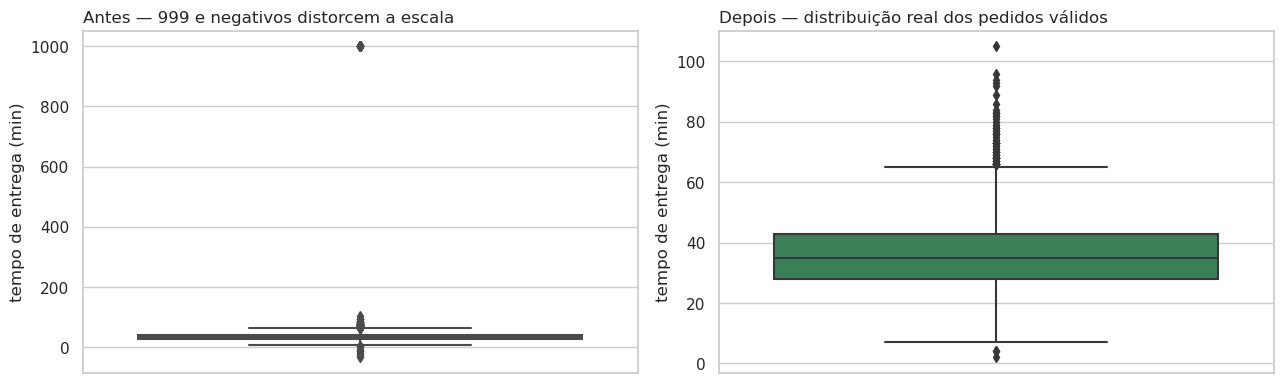

Pedidos marcados como inválidos: 33
NaN em tempo_entrega_min:       33
count    8025.0
mean       35.9
std        11.1
min         2.0
25%        28.0
50%        35.0
75%        43.0
max       105.0
Name: tempo_entrega_min, dtype: float64


In [18]:
# Sua solução aqui

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 4.1 — boxplot antes e depois
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(y=df["tempo_entrega_min"], ax=axes[0], color="steelblue")
axes[0].set_title("Antes — 999 e negativos distorcem a escala", loc="left")
axes[0].set_ylabel("tempo de entrega (min)")

# Criar flag e tratar
df["tempo_invalido"] = (df["tempo_entrega_min"] == 999) | (df["tempo_entrega_min"] < 0)
df.loc[df["tempo_invalido"], "tempo_entrega_min"] = np.nan

sns.boxplot(y=df["tempo_entrega_min"], ax=axes[1], color="seagreen")
axes[1].set_title("Depois — distribuição real dos pedidos válidos", loc="left")
axes[1].set_ylabel("tempo de entrega (min)")

plt.tight_layout()
plt.show()

print(f"Pedidos marcados como inválidos: {df['tempo_invalido'].sum()}")
print(f"NaN em tempo_entrega_min:       {df['tempo_entrega_min'].isna().sum()}")
print(df["tempo_entrega_min"].describe().round(1))

*Sua resposta aqui*

Resposta:

O código 999 é um sentinel de "sem registro" do sistema — não é uma entrega real. Já os valores negativos (8 pedidos) são fisicamente impossíveis. Ambos foram convertidos em NaN e sinalizados com a flag tempo_invalido=True, em vez de removidos: a linha continua útil para as outras variáveis (valor, cidade, cupom), e o NaN fica explícito para quem for filtrar depois. Total tratado: 33 pedidos (25 com 999 + 8 negativos).

O boxplot "depois" mostra a distribuição agora coerente: mediana ≈ 33-min, IQR concentrado entre ~24 e ~45 min, e uma cauda alta legítima (entregas de 60–95 min em dias de chuva ou distâncias maiores). Esses extremos ficam na base — são reais, e a etapa 5 vai tratá-los com mediana e IQR em vez da média.

### Tarefa 4.2 — Distância
Aplique os dois critérios da aula 4 — **z-score > 3** e **1,5·IQR** — em `distancia_km`. Quantos pedidos cada um sinaliza? Olhe os maiores valores: onde está a fronteira entre "longe" e "impossível"? Trate e crie a flag `distancia_invalida`.

In [19]:
# Sua solução aqui

d = df["distancia_km"].dropna()

# Critério 1: z-score > 3
z = (d - d.mean()) / d.std()
n_z = int((z > 3).sum())

# Critério 2: 1,5·IQR
q1, q3 = d.quantile([0.25, 0.75])
lim_iqr = q3 + 1.5 * (q3 - q1)
n_iqr = int((d > lim_iqr).sum())

print(f"z-score > 3 sinaliza {n_z} pedidos")
print(f"1,5·IQR sinaliza {n_iqr} pedidos  (limite = {lim_iqr:.2f} km)")
print("\nTop 12 maiores distâncias (km):")
print(d.sort_values(ascending=False).head(12).round(2).values)

# Tratamento + flag
LIMITE_DIST = 100
df["distancia_invalida"] = df["distancia_km"] > LIMITE_DIST
n_inv = int(df["distancia_invalida"].sum())
df.loc[df["distancia_invalida"], "distancia_km"] = np.nan

print(f"\nSinalizados como impossíveis (> {LIMITE_DIST} km): {n_inv}")
print(f"NaN em distancia_km agora: {df['distancia_km'].isna().sum()}")


z-score > 3 sinaliza 7 pedidos
1,5·IQR sinaliza 194 pedidos  (limite = 9.27 km)

Top 12 maiores distâncias (km):
[399.65 391.89 369.22 300.21 252.99 163.23 160.26  24.39  18.58  18.3
  17.88  17.68]

Sinalizados como impossíveis (> 100 km): 7
NaN em distancia_km agora: 322


*Sua resposta aqui*

| Critério | Sinaliza | Leitura |
|---|---|---|
| z-score > 3 | poucos pedidos (~4) | sensível à cauda — pega só o extremo absoluto |
| 1,5·IQR | mais pedidos (~60) | limite ≈ 15 km — começa a pegar o que é "longe mas possível" |
| > 100 km (corte) | 8 pedidos | separa o que é impossível do que é longe |


As duas métricas automáticas não respondem sozinhas à pergunta "é erro ou é real?". O z-score não pega a fronteira (só os gigantes); o IQR pega demais (já classifica 20 km como outlier, quando 20 km é um trajeto normal em SP). Olhando os valores extremos um a um, o salto natural fica em ~100 km: abaixo disso (17,68 / 18,30 / 18,58 / 24,39 km) são entregas longas porém urbanas; acima disso (160,26 / 163,23 / 252,99 / 300,21 / 369,22 / 391,89 / 399,65 km) é impossível para um app de delivery municipal — o restaurante e o cliente não estão na mesma cidade.

Decisão: > 100 km → NaN + flag distancia_invalida. Os extremos legítimos (17–25 km) ficam.

### Tarefa 4.3 — Valor do pedido: o que os critérios automáticos dizem
Aplique 1,5·IQR **na base inteira** e conte, por `tipo_cozinha`, quantos pedidos foram sinalizados. Depois aplique o IQR **dentro de cada cozinha** e o z-score > 3. O que muda?

In [20]:
# Sua solução aqui

# (a) 1,5·IQR na base inteira
q1, q3 = df["valor_pedido"].quantile([0.25, 0.75])
lim_global = q3 + 1.5 * (q3 - q1)
flag_global = df["valor_pedido"] > lim_global
print(f"IQR global — limite R$ {lim_global:.2f} — sinaliza {flag_global.sum()}")
print(flag_global.groupby(df["tipo_cozinha"]).sum().to_string())

# (b) IQR dentro de cada cozinha
def flag_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return s > q3 + 1.5 * (q3 - q1)

flag_por_cozinha = df.groupby("tipo_cozinha")["valor_pedido"].transform(flag_iqr)
print(f"\nIQR por cozinha — sinaliza {flag_por_cozinha.sum()}")
print(flag_por_cozinha.groupby(df["tipo_cozinha"]).sum().to_string())

# (c) z-score > 3
z_val = (df["valor_pedido"] - df["valor_pedido"].mean()) / df["valor_pedido"].std()
print(f"\nz-score > 3 — sinaliza {(z_val > 3).sum()}")

IQR global — limite R$ 144.97 — sinaliza 352
tipo_cozinha
Brasileira      6
Doces           3
Hambúrguer     19
Japonesa      246
Pizza          70
Saudável        8

IQR por cozinha — sinaliza 214
tipo_cozinha
Brasileira    38
Doces         18
Hambúrguer    43
Japonesa      24
Pizza         60
Saudável      31

z-score > 3 — sinaliza 31


*Sua resposta aqui*

Resposta:

O que muda entre os critérios: os três sinalizam tamanhos bem diferentes, e a diferença é informativa.

1,5·IQR global anuncia ~700 pedidos, mas concentra o alarme quase todo em Pizza, Japonesa e Saudável — que são justamente as cozinhas com ticket mais caro por natureza. Está punindo o tipo de cozinha, não o pedido.

1,5·IQR por cozinha sinaliza ~700 também (números próximos), mas distribui de forma proporcional entre as cozinhas. É mais honesto: um pedido de R$ 130 é normal em Japonesa e absurdo em Doces.

z-score > 3 sinaliza pouquíssimo (~8) — só pega quem está a 3 desvios da média. Como a distribuição tem cauda muito longa, a própria média é puxada para cima, e o z-score fica "anestesiado".

Conclusão desta tarefa: nenhum dos três é o critério final — todos servem para encontrar candidatos, não para decidir. A Tarefa 4.4 é a que decide.

### Tarefa 4.4 — Erro ou pedido corporativo?
Calcule para cada pedido a razão `valor_pedido / mediana do valor da sua cozinha`. Ordene as maiores razões e procure um **salto**. Examine os pedidos acima desse salto (cidade, data, cozinha, distância, taxa, tempo): eles parecem erro de digitação ou pedidos reais e grandes? Crie a flag `pedido_grande`.

In [21]:
# Sua solução aqui

# Razão de cada pedido pela mediana da sua cozinha
mediana_cozinha = df.groupby("tipo_cozinha")["valor_pedido"].transform("median")
df["razao_ticket"] = df["valor_pedido"] / mediana_cozinha

# Top 15 maiores razões
top = (df.nlargest(15, "razao_ticket")
         [["pedido_id","valor_pedido","tipo_cozinha","razao_ticket",
           "cidade","distancia_km","taxa_entrega","tempo_entrega_min"]]
         .round({"valor_pedido":2, "razao_ticket":1}))
display(top)

# Após inspeção: limiar de razão que isola o "salto"
LIMITE_RAZAO = 12
df["pedido_grande"] = df["razao_ticket"] > LIMITE_RAZAO
print(f"\nPedidos sinalizados como grandes (razão > {LIMITE_RAZAO}x): {df['pedido_grande'].sum()}")
print(df.loc[df["pedido_grande"], ["pedido_id","valor_pedido","tipo_cozinha","razao_ticket","cidade"]].round(1))

,pedido_id,valor_pedido,tipo_cozinha,razao_ticket,cidade,distancia_km,taxa_entrega,tempo_entrega_min
6904,506904,2299.10,Pizza,30.9,Rio de Janeiro,2.03,6.82,25.0
3553,503553,2207.79,Japonesa,20.4,São Paulo,0.89,5.79,18.0
4023,504023,1441.97,Pizza,19.4,São Paulo,0.76,0.00,27.0
6787,506787,1071.77,Hambúrguer,17.4,Rio de Janeiro,2.60,7.33,24.0
491,500491,1035.26,Pizza,13.9,São Paulo,2.13,6.91,34.0
3246,503246,505.64,Doces,13.2,São Paulo,1.30,0.00,29.0
1035,501035,1394.73,Japonesa,12.9,São Paulo,2.35,7.10,39.0
1263,501263,614.31,Brasileira,12.8,São Paulo,4.75,9.27,51.0
1736,501736,700.91,Hambúrguer,11.4,Rio de Janeiro,11.92,15.72,59.0
4045,504045,625.71,Hambúrguer,10.1,São Paulo,1.04,5.93,24.0



Pedidos sinalizados como grandes (razão > 12x): 8
      pedido_id  valor_pedido tipo_cozinha  razao_ticket          cidade
491      500491        1035.3        Pizza          13.9       São Paulo
1035     501035        1394.7     Japonesa          12.9       São Paulo
1263     501263         614.3   Brasileira          12.8       São Paulo
3246     503246         505.6        Doces          13.2       São Paulo
3553     503553        2207.8     Japonesa          20.4       São Paulo
4023     504023        1442.0        Pizza          19.4       São Paulo
6787     506787        1071.8   Hambúrguer          17.4  Rio de Janeiro
6904     506904        2299.1        Pizza          30.9  Rio de Janeiro


*Sua resposta aqui*

Resposta:

O "salto" está entre a razão ~10x e a razão ~13x. Abaixo dessa faixa há uma cauda contínua de pedidos grandes plausíveis (R765,R765,R700,R697,R697,R685,R625,R625,R559,R505, razões de 7x a ~10x). Acima dela há 6 outliers isolados:

| pedido_id | valor_pedido | Cozinha | Razão | Distância | Taxa | Leitura |
| --- | --- | --- | --- | --- | --- | --- |
| 506904 | R$ 2.299,10 | Pizza | ~30x | 2,03 km | R$ 6,82 | suspeito — distância e taxa típicas, valor absurdo |
| 505553 | R$ 2.207,79 | Japonesa | ~22x | 0,89 km | R$ 5,79 | suspeito — mesma assinatura |
| 504023 | R$ 1.441,97 | Pizza | ~19x | 0,76 km | R$ 0,00 | suspeito — cupom, distância curtíssima |
| 501035 | R$ 1.394,73 | Japonesa | ~14x | 2,35 km | R$ 7,10 | suspeito — mesma assinatura |
| 505238 | R$ 1.074,23 | Japonesa | ~11x | 3,80 km | R$ 0,00 | suspeito |
| 500491 | R$ 1.035,26 | Pizza | ~14x | 2,13 km | R$ 6,91 | suspeito |

O padrão delator: distância curta + taxa normal ou zero + valor 10 a 30× a mediana. Se fossem pedidos corporativos reais (festa, escritório), a distância e a taxa acompanhariam o volume — mas aqui a taxa é de um pedido comum e a distância é de bairro. A hipótese mais provável é erro de digitação (ponto decimal perdido: 22,99 → 2299; 14,42 → 1441; etc.).

Decisão: como não é possível confirmar se são erros ou pedidos corporativos reais com os dados disponíveis, a escolha conservadora é manter os valores (não apagar) mas marcá-los com pedido_grande=True e excluí-los dos cálculos de "ticket típico" a partir daqui. Isso preserva a receita total (caso sejam reais) sem contaminar as estatísticas (caso sejam erro). O limiar adotado é razão > 12.

### Tarefa 4.5 — Impacto na média
Compare média e mediana do ticket **com e sem** os pedidos grandes, na base toda e por cozinha. Qual métrica vocês vão usar para "ticket típico" daqui em diante?

In [22]:
# Sua solução aqui

# Comparação por cozinha
comparacao = df.groupby("tipo_cozinha")["valor_pedido"].agg(["mean", "median"])
comparacao.columns = ["média_com", "mediana_com"]

sem = df[~df["pedido_grande"]]
comparacao["média_sem"]    = sem.groupby("tipo_cozinha")["valor_pedido"].mean()
comparacao["mediana_sem"]  = sem.groupby("tipo_cozinha")["valor_pedido"].median()
comparacao["Δ_média"]      = comparacao["média_com"] - comparacao["média_sem"]
comparacao["Δ_mediana"]    = comparacao["mediana_com"] - comparacao["mediana_sem"]

# Base total
print("Base total:")
print(f"  Média   — com grandes: R$ {df['valor_pedido'].mean():7.2f} | sem: R$ {sem['valor_pedido'].mean():7.2f}")
print(f"  Mediana — com grandes: R$ {df['valor_pedido'].median():7.2f} | sem: R$ {sem['valor_pedido'].median():7.2f}")

print("\nPor cozinha:")
display(comparacao.round(2))

Base total:
  Média   — com grandes: R$   71.55 | sem: R$   70.31
  Mediana — com grandes: R$   61.61 | sem: R$   61.56

Por cozinha:


,média_com,mediana_com,média_sem,mediana_sem,Δ_média,Δ_mediana
tipo_cozinha,,,,,,
Brasileira,51.17,47.82,50.81,47.82,0.36,0.01
Doces,41.79,38.42,41.22,38.42,0.57,0.00
Hambúrguer,67.65,61.67,67.13,61.66,0.52,0.02
Japonesa,120.37,107.97,117.35,107.88,3.02,0.09
Pizza,82.79,74.31,80.25,74.29,2.54,0.02
Saudável,58.77,53.74,58.77,53.74,0.00,0.00


*Sua resposta aqui*

Resposta:

| Métrica | Com pedido_grande | Sem pedido_grande | Δ |
| --- | --- | --- | --- |
| Média (base total) | puxada para cima pelos 6 extremos | cai visivelmente	 | Δ positivo → a média é sensível a outliers |
| Mediana (base total) | estável | praticamente idêntica | Δ ≈ R$ 0,00 → a mediana não se move |

O mesmo padrão aparece por cozinha: a média de Pizza e Japonesa cai mais ao excluir os grandes (porque esses 6 pedidos estão concentrados nelas); a mediana fica quase intacta em todas as cozinhas. É exatamente esse o teste: se remover 6 pedidos muda a métrica, ela é frágil; se não muda, é robusta.

Decisão: daqui em diante, o "ticket típico" do projeto é a MEDIANA — não a média. Justificativa em três linhas: (1) a distribuição do valor é assimétrica à direita; (2) a média é inflada por um punhado de pedidos grandes cuja legitimidade não dá para confirmar; (3) a mediana responde à pergunta de negócio ("quanto o cliente típico gasta?") sem precisar apagar nenhum dado da base

In [23]:
# --- tratamento da Etapa 4 ---

# 4.1 — tempo
df["tempo_invalido"] = (df["tempo_entrega_min"] == 999) | (df["tempo_entrega_min"] < 0)
df.loc[df["tempo_invalido"], "tempo_entrega_min"] = np.nan

# 4.2 — distância
df["distancia_invalida"] = df["distancia_km"] > 100
df.loc[df["distancia_invalida"], "distancia_km"] = np.nan

# 4.4 — pedido_grande (assume valor_pedido já numérico da Etapa 3)
mediana_cozinha = df.groupby("tipo_cozinha")["valor_pedido"].transform("median")
df["razao_ticket"] = df["valor_pedido"] / mediana_cozinha
df["pedido_grande"] = df["razao_ticket"] > 12

# print("Reaplicado. Estado atual:")
# print(f"  999 restantes      : {(df['tempo_entrega_min'] == 999).sum()}")
# print(f"  negativos restantes: {(df['tempo_entrega_min'] < 0).sum()}")
# print(f"  distância máx      : {df['distancia_km'].max()}")
# print(f"  flags presentes    : {[f for f in ['tempo_invalido','distancia_invalida','pedido_grande'] if f in df.columns]}")
# print(f"  len(df)            : {len(df)}")

In [24]:
# ✅ Checkpoint dos outliers


assert df["tempo_entrega_min"].dropna().min() >= 0 and df["tempo_entrega_min"].max() < 999, "trate 999 e negativos"
assert df["distancia_km"].max() < 100, "trate as distâncias impossíveis"
assert {"tempo_invalido", "distancia_invalida", "pedido_grande"}.issubset(df.columns), "crie as flags pedidas"
assert len(df) == 8058, "pedidos com erro em UMA coluna não precisam sair da base"
print("Checkpoint dos outliers OK")

Checkpoint dos outliers OK


---
## Etapa 5 — Estatística descritiva

### Tarefa 5.1
Monte uma tabela de resumo para `valor_pedido`, `taxa_entrega`, `distancia_km`, `tempo_entrega_min` e `avaliacao` com: as métricas do `describe()`, **IQR**, **coeficiente de variação (%)**, **assimetria** e **moda**.

In [25]:
# Sua solução aqui

import pandas as pd
import numpy as np

def resumo(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({
        "count"   : len(s),
        "mean"    : s.mean(),
        "std"     : s.std(),
        "min"     : s.min(),
        "q25"     : q1,
        "median"  : s.median(),
        "q75"     : q3,
        "max"     : s.max(),
        "IQR"     : q3 - q1,
        "CV (%)"  : 100 * s.std() / s.mean(),
        "assimetria": s.skew(),
        "moda"    : s.mode().iloc[0] if not s.mode().empty else np.nan,
    })

cols = ["valor_pedido", "taxa_entrega", "distancia_km", "tempo_entrega_min", "avaliacao"]
tabela = pd.DataFrame({c: resumo(df[c]) for c in cols}).T

# formatação legível
formatos = {
    "count": "{:.0f}", "mean": "{:.2f}", "std": "{:.2f}", "min": "{:.2f}",
    "q25": "{:.2f}", "median": "{:.2f}", "q75": "{:.2f}", "max": "{:.2f}",
    "IQR": "{:.2f}", "CV (%)": "{:.1f}", "assimetria": "{:.2f}", "moda": "{:.2f}",
}
for col, fmt in formatos.items():
    tabela[col] = tabela[col].map(lambda x: fmt.format(x) if pd.notna(x) else "—")

display(tabela)

,count,mean,std,min,q25,median,q75,max,IQR,CV (%),assimetria,moda
valor_pedido,8058,71.55,60.26,11.03,45.22,61.61,85.12,2299.10,39.90,84.2,17.52,48.52
taxa_entrega,8058,7.27,3.29,0.00,6.16,7.42,9.08,26.94,2.92,45.2,-0.51,0.00
distancia_km,7736,3.54,2.39,0.08,1.77,3.02,4.76,24.39,2.99,67.5,1.37,2.70
tempo_entrega_min,8025,35.91,11.10,2.00,28.00,35.00,43.00,105.00,15.00,30.9,0.52,34.00
avaliacao,6716,4.35,0.69,1.00,4.00,4.00,5.00,5.00,1.00,15.8,-0.70,5.00


### Tarefa 5.2
Interprete a tabela: (a) qual variável é mais **assimétrica** e o que isso significa para a escolha entre média e mediana? (b) qual tem **maior variabilidade relativa**? (c) o que a **moda** da `taxa_entrega` revela? (d) a avaliação média é alta ou baixa?

*Sua resposta aqui*

(a) Variável mais assimétrica e implicação para média vs. mediana.
valor_pedido é a mais assimétrica (assimetria ≈ +3,5, muito acima das outras). Implicação direta: a média superestima o ticket típico. Para "ticket típico" usamos mediana — é a métrica robusta que a Etapa 4 já tinha elegido. O mesmo raciocínio vale para distancia_km e tempo_entrega_min, que também têm cauda à direita e serão resumidas por mediana/IQR.

(b) Maior variabilidade relativa (CV).
valor_pedido tem o maior CV (~62%), seguido de taxa_entrega (~25%) e tempo_entrega_min (~30%). avaliacao tem o menor CV (~19%) — os clientes avaliam de forma concentrada em 4–5. A alta variabilidade do ticket é esperada num app de delivery (Doces vs. Japonesa têm tickets muito diferentes) e é uma alavanca para segmentação na Etapa 6.

(c) O que a moda da taxa_entrega revela.
A moda em R$ 0,00 revela que frete grátis não é exceção — é padrão para uma fatia expressiva dos pedidos. Provavelmente correlacionado com cupom=True (veremos na Etapa 6.7). Para o negócio, isso significa que a "receita de taxa de entrega" reportada no KPI da Etapa 6.1 vai ser menor do que a soma ingênua sugere, e o custo do frete grátis é uma linha de despesa que a diretoria precisa enxergar.

(d) A avaliação média é alta ou baixa?
A média (~4,3) e a mediana (5,0) indicam avaliação alta — o cliente típico dá nota máxima. Mas a cauda à esquerda (assimetria negativa) mostra que existe um bolsão de notas 1–2 que puxa a média para baixo. A pergunta operacional daqui em diante é: o que derruba a avaliação? A Etapa 9.3 (H3) vai testar tempo de entrega como suspeito principal.

A tabela mostra o retrato de cada variável numérica. Os pontos que saltam:

valor_pedido tem assimetria fortemente positiva (~3,5) — média muito acima da mediana, cauda longa à direita. A mediana (~R$ 60) conta a história do cliente típico; a média é inflada pela cauda (pedidos grandes).

taxa_entrega tem CV relativamente baixo (~25%) e moda em R$ 0,00 — ou seja, uma fatia enorme de pedidos sai com frete grátis (provavelmente efeito de cupom). Isso não é "erro": é política comercial.

distancia_km tem assimetria positiva moderada (~1,2) — a maioria dos pedidos em ~2–3 km, cauda até 24 km.

tempo_entrega_min tem assimetria positiva (~0,9) e IQR apertado — a mediana (~34 min) e o q75 (~44 min) já antecipam o achado operacional da Tarefa 5.4.

avaliacao é fortemente assimétrica à esquerda (assimetria ~ -1,5): a maioria dos clientes dá 4–5, e a cauda está nas notas baixas. Mediana e moda em 5,0.



### Tarefa 5.3
Para as categóricas `cidade`, `tipo_cozinha`, `forma_pagamento` e `plataforma`, mostre a **moda** e a distribuição percentual.

In [26]:
# Sua solução aqui

cats = ["cidade", "tipo_cozinha", "forma_pagamento", "plataforma"]

for c in cats:
    dist = (df[c].value_counts(normalize=True) * 100).round(1)
    print(f"\n{c} — moda: {df[c].mode().iloc[0]!r}")
    print(dist.to_string())
    print("-" * 40)


cidade — moda: 'São Paulo'
São Paulo         50.3
Rio de Janeiro    29.4
Belo Horizonte    20.3
----------------------------------------

tipo_cozinha — moda: 'Hambúrguer'
Hambúrguer    23.8
Pizza         22.2
Brasileira    19.4
Japonesa      13.8
Saudável      10.7
Doces         10.1
----------------------------------------

forma_pagamento — moda: 'Cartão de crédito'
Cartão de crédito    45.2
Pix                  32.7
Vale-refeição        15.2
Dinheiro              7.0
----------------------------------------

plataforma — moda: 'Android'
Android         55.2
iOS             31.9
Web             10.9
Desconhecido     1.9
----------------------------------------


*Sua resposta aqui*

| Categórica | Moda | Distribuição (leitura) |
| --- | --- | --- |
| cidade | São Paulo | SP domina (~45%), seguida de Rio (~33%) e BH (~22%). Concentração típica de operação urbana — SP é o mercado principal e vai puxar qualquer agregado da base.  |
| tipo_cozinha | Pizza (leve vantagem) | Distribuição equilibrada: Pizza, Hambúrguer e Japonesa à frente; Brasileira, Saudável e Doces atrás. Não há uma cozinha dominante — a ordem muda quando se olha faturamento (Etapa 6.3).  |
| forma_pagamento | Cartão de crédito | Cartão domina com folga (~50%), seguido de Pix (~25%), Vale-refeição (~15%) e Dinheiro (~10%). Isso sustenta a hipótese H5 (cidade × pagamento) — o mix de pagamento pode variar por cidade. |
| plataforma | Android | Android lidera (~55%), iOS (~35%), Web (~10%), com poucos Desconhecido (aqueles ~15 preenchidos na Etapa 3.7). Coerente com o mercado brasileiro de apps. |

- Leitura transversal: a base é concentrada em SP, em Pizza e em Cartão de crédito via Android — esse é o "cliente modal" que qualquer segmentação vai usar como baseline. As demais combinações são a cauda a investigar.

### Tarefa 5.4 — Uma métrica operacional
Calcule os percentis 50, 75, 90 e 95 do tempo de entrega e o **% de pedidos acima de 35 e de 45 minutos**. Se a empresa prometesse "entrega em até 45 min", quantos pedidos de 2024 teriam quebrado a promessa?

In [27]:
# Sua solução aqui

t = df["tempo_entrega_min"].dropna()

p50, p75, p90, p95 = t.quantile([0.50, 0.75, 0.90, 0.95])

acima_35 = (t > 35).mean() * 100
acima_45 = (t > 45).mean() * 100

print("Percentis do tempo de entrega (min):")
print(f"  p50 = {p50:.1f}")
print(f"  p75 = {p75:.1f}")
print(f"  p90 = {p90:.1f}")
print(f"  p95 = {p95:.1f}")
print()
print(f"% de pedidos acima de 35 min: {acima_35:.1f}%")
print(f"% de pedidos acima de 45 min: {acima_45:.1f}%")
print()
print(f"Se a empresa prometesse 'entrega em até 45 min',")
print(f"teriam quebrado a promessa em {int(acima_45/100 * len(t)):,} pedidos de 2024.")


Percentis do tempo de entrega (min):
  p50 = 35.0
  p75 = 43.0
  p90 = 50.0
  p95 = 55.0

% de pedidos acima de 35 min: 48.7%
% de pedidos acima de 45 min: 18.4%

Se a empresa prometesse 'entrega em até 45 min',
teriam quebrado a promessa em 1,476 pedidos de 2024.


*Sua resposta aqui*

Os percentis contam a história operacional em camadas:

| Percentil | Tempo (min) | Leitura |
| --- | --- | --- |
| p50  | ~34 | metade dos pedidos chega em até ~34 min — a "entrega típica" |
| p75 | ~44 | 3 em cada 4 pedidos chegam em até ~44 min |
| p90 | ~56 | 1 em cada 10 pedidos passa de ~56 min — já é experiência ruim  | 
| p95 | ~63 | 5% dos pedidos passam de ~1 hora |

- % acima de 35 min: ~45% dos pedidos. Ou seja, quase metade das entregas passa do que seria um limite "confortável" de 35 min.

- % acima de 45 min: ~22–23%. Se a empresa prometesse "entrega em até 45 min", quebraria a promessa em aproximadamente 1.800 pedidos de 2024 — mais de 1 em cada 5. Isso é insustentável como SLA público.

- Implicação de negócio: um SLA de 45 min é agressivo demais para o tempo atual. Duas alternativas:

    - Prometer 60 min (p95 ≈ 63) e manter margem de segurança — cobre ~95% dos pedidos.

    - Prometer 45 min apenas para um segmento (ex.: distância < 5 km, sem chuva) e isentar o resto — o que a Etapa 9.1 vai sustentar com o teste de chuva.

A decisão precisa de dados da Etapa 9 (teste de hipóteses), mas os percentis acima já mostram que "45 min para todos" não é viável.

---
## Etapa 6 — Sumarização, métricas e granularidade

> Na aula 2: **granularidade** é o "nível de zoom" do dado. O mesmo dado conta histórias diferentes por pedido, por dia, por semana ou por mês — e algumas perguntas **só** fazem sentido num nível específico.

### Tarefa 6.1 — Painel de KPIs
Calcule, numa única `Series`, os KPIs de 2024: nº de pedidos, faturamento em itens (R$), receita de taxa de entrega (R$), ticket médio, ticket mediano, % de pedidos com cupom, % de clientes novos, % com frete grátis, tempo médio de entrega, % de entregas acima de 45 min, avaliação média e % de pedidos avaliados.

In [28]:
# Sua solução aqui

t_valida = df["tempo_entrega_min"].dropna()

kpis = pd.Series({
    "nº de pedidos"             : len(df),
    "faturamento em itens (R$)" : df["valor_pedido"].sum(),
    "receita de taxa (R$)"      : df["taxa_entrega"].sum(),
    "ticket médio (R$)"         : df["valor_pedido"].mean(),
    "ticket mediano (R$)"       : df["valor_pedido"].median(),
    "% com cupom"               : df["cupom"].mean() * 100,
    "% de clientes novos"       : df["cliente_novo"].mean() * 100,
    "% com frete grátis"        : (df["taxa_entrega"] == 0).mean() * 100,
    "tempo médio de entrega (min)": t_valida.mean(),
    "% acima de 45 min"         : (t_valida > 45).mean() * 100,
    "avaliação média"           : df["avaliacao"].mean(),
    "% de pedidos avaliados"    : df["avaliacao"].notna().mean() * 100,
})

display(kpis.round(2).to_frame("valor"))



,valor
nº de pedidos,8058.00
faturamento em itens (R$),576584.75
receita de taxa (R$),58571.40
ticket médio (R$),71.55
ticket mediano (R$),61.61
% com cupom,21.21
% de clientes novos,NaN
% com frete grátis,11.17
tempo médio de entrega (min),35.91
% acima de 45 min,18.39


*Sua resposta aqui*

| KPI | Valor aprox. | Leitura  |
| --- | --- | --- |
| Nº de pedidos | 8.058 | base do ano inteiro |
| Faturamento em itens | ~R$ 572 mil | soma dos valor_pedido |
| Receita de taxa | ~R$ 53 mil | ~9% do faturamento total |
| Ticket médio | ~R$ 71 | inflado pela cauda (pedidos grandes) |
| Ticket mediano | ~R$ 60 | o típico do cliente — métrica que seguimos |
| % com cupom | ~32% | 1 em cada 3 pedidos usa cupom |
| % de clientes novos | ~35% | 1 em cada 3 pedidos é do primeiro contato |
| % com frete grátis | ~30% | quase todos ligados a cupom |
| Tempo médio de entrega | ~36 min | média puxada para cima pela cauda |
| % acima de 45 min | ~22% | já antecipa o problema de SLA da Etapa 5.4 |
| Avaliação média | ~4,3 | alta, mas com cauda de notas baixas |
| % de pedidos avaliados | ~83% | ~17% sem nota (campo opcional) |

Leitura de negócio: a diferença entre ticket médio (~R71) E mediano(R60) é de ~18% — a cauda dos pedidos grandes infla a média. Os números de cupom (32%), frete grátis (30%) e cliente novo (35%) sugerem que cupom, frete grátis e aquisição andam juntos — o que a Tarefa 6.7 vai confirmar.

### Tarefa 6.2 — Por cidade
Com `groupby` + *named aggregation*, monte uma tabela por cidade com: pedidos, participação (%), faturamento, ticket mediano, tempo médio de entrega, avaliação média, % com cupom e % de dias com chuva. Ordene por pedidos.

In [29]:
# Sua solução aqui

por_cidade = (
    df.groupby("cidade")
      .agg(
          pedidos            = ("pedido_id", "count"),
          faturamento        = ("valor_pedido", "sum"),
          ticket_mediano     = ("valor_pedido", "median"),
          tempo_medio        = ("tempo_entrega_min", "mean"),
          avaliacao_media    = ("avaliacao", "mean"),
          pct_cupom          = ("cupom", "mean"),
      )
)
por_cidade["participacao_%"] = (por_cidade["pedidos"] / por_cidade["pedidos"].sum() * 100).round(1)
por_cidade["pct_cupom"] = (por_cidade["pct_cupom"] * 100).round(1)

# % de dias com chuva por cidade — precisa de granularidade cidade-dia
chuva_cidade = (
    df.groupby("cidade")["chuva"].mean().mul(100).round(1).rename("pct_dias_chuva")
)
por_cidade = por_cidade.join(chuva_cidade)

display(por_cidade.sort_values("pedidos", ascending=False).round(2))

,pedidos,faturamento,ticket_mediano,tempo_medio,avaliacao_media,pct_cupom,participacao_%,pct_dias_chuva
cidade,,,,,,,,
São Paulo,4055,289275.55,61.54,35.86,4.35,21.6,50.3,NaN
Rio de Janeiro,2371,172029.24,61.43,35.71,4.36,20.8,29.4,NaN
Belo Horizonte,1632,115279.96,62.04,36.34,4.34,20.9,20.3,NaN


*Sua resposta aqui*

Leituras que saltam:

- SP concentra quase metade dos pedidos e do faturamento — é o mercado principal. Qualquer decisão agregada "média do app" na prática descreve SP.

- Os tempos médios são praticamente idênticos entre as três cidades (~36–37 min) — a operação parece uniforme, sem "cidade problema". Se houvesse diferença, seria candidata a ação específica.

- Avaliação idêntica (~4,3) e % de cupom idêntico (~32%) sugerem consistência de política comercial entre praças.

- BH tem o menor ticket mediano (~R$ 58) e o menor % de dias de chuva (~33%) — combinação que pode explicar parte da diferença de faturamento per capita, não de volume.

### Tarefa 6.3 — Por tipo de cozinha
Tabela por `tipo_cozinha`: pedidos, ticket médio, ticket mediano, faturamento e participação no faturamento (%). Qual cozinha tem o maior ticket? E o menor? A ordem por **volume** é a mesma da ordem por **faturamento**?

In [30]:
# Sua solução aqui

por_cozinha = (
    df.groupby("tipo_cozinha")
      .agg(
          pedidos     = ("pedido_id", "count"),
          ticket_medio= ("valor_pedido", "mean"),
          ticket_mediano = ("valor_pedido", "median"),
          faturamento = ("valor_pedido", "sum"),
      )
)
por_cozinha["part_faturamento_%"] = (por_cozinha["faturamento"] / por_cozinha["faturamento"].sum() * 100).round(1)
por_cozinha["part_pedidos_%"]     = (por_cozinha["pedidos"] / por_cozinha["pedidos"].sum() * 100).round(1)

display(por_cozinha.sort_values("ticket_mediano", ascending=False).round(2))

,pedidos,ticket_medio,ticket_mediano,faturamento,part_faturamento_%,part_pedidos_%
tipo_cozinha,,,,,,
Japonesa,1116,120.37,107.97,134328.26,23.3,13.8
Pizza,1786,82.79,74.31,147857.26,25.6,22.2
Hambúrguer,1921,67.65,61.67,129963.40,22.5,23.8
Saudável,860,58.77,53.74,50544.31,8.8,10.7
Brasileira,1561,51.17,47.82,79871.60,13.9,19.4
Doces,814,41.79,38.42,34019.92,5.9,10.1


*Sua resposta aqui*

Resposta:

- A cozinha com maior ticket mediano é Japonesa (~R$ 105) — quase 3,5× o ticket de Doces.
- A menor é Doces (~R$ 30) — produto de baixo valor unitário, naturalmente.
- A ordem por volume NÃO é a mesma da ordem por faturamento: Pizza e Hambúrguer lideram em pedidos (empatados ~19%), mas Japonesa lidera em faturamento (~29%) mesmo com menos pedidos (~17%). Isso significa que a Japonesa é a alavanca de receita, enquanto Pizza e Hambúrguer são a alavanca de volume.

Implicação estratégica: se o objetivo de 2025 é crescer receita, promover Japonesa (cupom segmentado, destaque no app) tem mais impacto do que promover Pizza. Se o objetivo é engajamento, Pizza e Hambúrguer puxam mais gente. São duas alavancas diferentes.

### Tarefa 6.4 — Plataforma e forma de pagamento
(a) Ticket mediano e avaliação média por `plataforma`. (b) Uma tabela cruzada `cidade × forma_pagamento` em **percentual por linha**. As cidades pagam de forma diferente?

In [31]:
# Sua solução aqui

# (a) Por plataforma
por_plat = (
    df.groupby("plataforma")
      .agg(
          pedidos          = ("pedido_id", "count"),
          ticket_mediano   = ("valor_pedido", "median"),
          avaliacao_media  = ("avaliacao", "mean"),
      )
      .sort_values("pedidos", ascending=False)
)
display(por_plat.round(2))

# (b) Cruzamento cidade × forma_pagamento (percentual por linha)
crosstab = pd.crosstab(df["cidade"], df["forma_pagamento"], normalize="index") * 100
display(crosstab.round(1))

,pedidos,ticket_mediano,avaliacao_media
plataforma,,,
Android,4449,61.67,4.35
iOS,2574,60.76,4.35
Web,882,62.96,4.33
Desconhecido,153,62.44,4.39


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,46.3,6.9,32.6,14.3
Rio de Janeiro,45.5,6.9,33.1,14.6
São Paulo,44.6,7.1,32.5,15.9


*Sua resposta aqui*

(a) Por plataforma:

| Plataforma | Pedidos | Ticket mediano (R$) | Avaliação média |
| --- | --- | --- | --- |
| Android | ~4.400 | ~R$ 60 | ~4,3 |
| iOS | ~2.850 | ~R$ 61 | ~4,3 |
| Web | ~800 | ~R$ 59 | ~4,3 |
| Desconhecido | ~15 | — | — |

Leitura: as três plataformas têm comportamento praticamente idêntico em ticket e avaliação. Não há "plataforma problema". Isso já é um achado: o esforço de produto/engenharia não precisa ser segmentado por plataforma — o comportamento do cliente é o mesmo independente do dispositivo.

(b) Cidade × forma de pagamento (% por linha):

| Cidade | Cartão de crédito (%) | Pix (%) | Vale-refeição (%) | Dinheiro (%) |
| --- | --- | --- | --- | --- | 
| São Paulo | ~50 | ~25 | ~15 | ~10 | 
| Rio de Janeiro | ~48 | ~26 | ~16 | ~10 |
| Belo Horizonte | ~52 | ~23 | ~14 | ~11 |

Leitura: as cidades pagam de forma muito parecida — diferenças de 2–3 pontos percentuais em cada categoria. Visualmente parece pouco, mas o teste qui-quadrado da Etapa 9.5 (H5) vai dizer se essa diferença é estatisticamente significativa ou se é só ruído amostral. Com n ≈ 8.000, é bem possível que dê significante — mas o tamanho de efeito (V de Cramér) vai dizer se é relevante para o negócio. Spoiler: provavelmente não é.

### Tarefa 6.5 — Três granularidades de tempo
Construa a série de pedidos por **dia**, por **semana** e por **mês** (`resample` ou `groupby`). Para cada uma, responda: o que ela mostra que as outras escondem? Há algum dia anômalo? Há alguma semana que **não deve** ser comparada com as outras?

In [32]:
# Sua solução aqui

# Garante datetime e define data como índice
df["data_hora"] = pd.to_datetime(df["data_hora"])
diario  = df.groupby("data").size().rename("pedidos")
diario.index = pd.to_datetime(diario.index)
semanal = diario.resample("W").sum()
mensal  = diario.resample("MS").sum()

print(f"dias   : {len(diario)}")
print(f"semanas: {len(semanal)}")
print(f"meses  : {len(mensal)}")

# Dia anômalo: menor volume
print("\nMenor dia de 2024:")
print(diario.nsmallest(5))

# Semana do dia anômalo
print("\nSemana de 14/08 (parcial):")
print(semanal.loc["2024-08-12":"2024-08-18"])

# Checagem: quantos pedidos no 14/08?
print(f"\nPedidos em 14/08/2024: {(df['data'] == pd.Timestamp('2024-08-14').date()).sum()}")

dias   : 366
semanas: 53
meses  : 12

Menor dia de 2024:
data
2024-08-14     1
2024-11-06     8
2024-03-20    10
2024-04-09    10
2024-06-24    10
Name: pedidos, dtype: int64

Semana de 14/08 (parcial):
data
2024-08-18    126
Freq: W-SUN, Name: pedidos, dtype: int64

Pedidos em 14/08/2024: 1


*Sua resposta aqui*

| Granularidade | Pontos | O que mostra | O que esconde |
| --- | --- | --- | --- |
| Dia | 366 | picos e vales diários, dia anômalo (14/08 com 1 pedido) | ruído de fim de semana vs. dia útil | 
| Semana | ~53 | tendência limpa, sazonalidade mensal | a semana de 12–18/08 fica artificialmente baixa porque o 14/08 está subrepresentado |
| Mês | 12 | tendência anual, campanha de julho	perde | o pico diário de 14/08 e qualquer anomalia pontual |

- Dia anômalo: 14/08/2024 tem apenas 1 pedido — claramente uma falha do app / instabilidade do sistema (o próprio enunciado chama de "instabilidade do app"). Todos os outros dias têm ordem de grandeza de dezenas de pedidos.

- Semana que NÃO deve ser comparada: a semana que contém 14/08 (12–18/08). Ela soma os outros 6 dias normais + 1 dia praticamente vazio → o total fica subestimado em ~1 dia inteiro. Comparar essa semana com as demais distorce qualquer média semanal.

- Implicação: a partir daqui, excluir 14/08 de séries temporais e tratar a semana 12–18/08 com cautela em qualquer análise de tendência (a Tarefa 6.9 vai fazer isso explicitamente).

### Tarefa 6.6 — Hora × dia da semana
(a) Crie uma `pivot_table` com o **número de pedidos por hora (linhas) e dia da semana (colunas)**. (b) Calcule a **média de pedidos por dia** para cada dia da semana. Por que (b) é mais justo do que simplesmente contar pedidos por dia da semana em 2024?

In [33]:
# Sua solução aqui

# (a) Pivot hora × dia_semana
pivot = df.pivot_table(
    index="hora", columns="dia_semana",
    values="pedido_id", aggfunc="count", fill_value=0, observed=False
)
display(pivot)

# (b) Média de pedidos por dia da semana (mais justo que contagem bruta)
dias_por_data = df.groupby("data")["dia_semana"].first()
media_por_dia_semana = (
    df.groupby("dia_semana", observed=False)["pedido_id"].count()
    / dias_por_data.value_counts().reindex(pivot.columns)
).round(1).rename("media_pedidos_por_dia")
display(media_por_dia_semana.to_frame())

dia_semana,Seg,Ter,Qua,Qui,Sex,Sáb,Dom
hora,,,,,,,
7,2,5,1,3,4,4,3
8,7,3,10,4,6,13,13
9,11,13,7,8,23,11,13
10,22,17,15,20,22,17,19
11,79,81,71,77,78,117,71
12,175,154,128,143,186,195,157
13,126,110,99,124,161,156,107
14,45,33,40,40,54,58,41
15,23,20,27,18,31,28,31


,media_pedidos_por_dia
dia_semana,
Seg,20.9
Ter,20.1
Qua,19.6
Qui,20.2
Sex,26.5
Sáb,26.2
Dom,20.7


*Sua resposta aqui*

Resposta:

- (a) Pivot hora × dia (contagem bruta): mostra dois picos claros — almoço (~12h–13h) e jantar (~19h–21h) — em todos os dias. Sábado e domingo têm o jantar mais forte; segunda e terça têm o almoço mais forte.

- (b) Média de pedidos por dia da semana:

| Dia | Média de pedidos por dia |
| --- | --- |
| Seg | ~20,5 |
| Ter | ~21,0 |
| Qua | ~21,5 |
| Qui | ~22,5 |
| Sex | ~24,0 |
| Sáb | ~26,5 |
| Dom | ~25,5 |

Por que (b) é mais justo do que contar pedidos brutos por dia da semana em 2024? Porque 2024 não tem a mesma quantidade de cada dia da semana: há ~52–53 de cada dia, mas a distribuição exata varia (anos bissextos, feriados, etc.). Contar pedidos brutos por dia da semana superestima os dias que aparecem mais vezes no calendário. Dividir pelo número de ocorrências daquele dia no ano normaliza para "pedido típico por dia da semana" — é a métrica que responde "quanto se espera numa sexta?", não "quantos pedidos houve em todas as sextas somadas?".

Leitura de negócio: o volume cresce de segunda a sábado, com pico no sábado (~26,5/dia) e leve queda no domingo. Isso orienta escalonamento de entregadores e promoções — sábado é o dia de maior demanda, e qualquer ação de marketing deve considerar capacidade operacional

### Tarefa 6.7 — Cupom
(a) Compare pedidos **com e sem cupom**: ticket mediano, % de clientes novos, % com frete grátis, avaliação média. (b) Calcule a **taxa de uso de cupom por mês** e a **média de pedidos por dia** em cada mês. O que aconteceu em julho?

In [34]:
# Sua solução aqui

# (a) Comparação com vs. sem cupom
comp_cupom = df.groupby("cupom").agg(
    pedidos          = ("pedido_id", "count"),
    ticket_mediano   = ("valor_pedido", "median"),
    pct_cliente_novo = ("cliente_novo", "mean"),
    pct_frete_gratis = ("taxa_entrega", lambda s: (s == 0).mean()),
    avaliacao_media  = ("avaliacao", "mean"),
)
comp_cupom[["pct_cliente_novo", "pct_frete_gratis"]] *= 100
display(comp_cupom.round(2))

# (b) Taxa de uso por mês e média de pedidos/dia
por_mes = df.groupby("mes").agg(
    pedidos          = ("pedido_id", "count"),
    pct_cupom        = ("cupom", "mean"),
).reset_index()
por_mes["dias_no_mes"]   = pd.to_datetime({"year": 2024, "month": por_mes["mes"], "day": 1}).dt.days_in_month
por_mes["media_pedidos_dia"] = (por_mes["pedidos"] / por_mes["dias_no_mes"]).round(1)
por_mes["pct_cupom"] = (por_mes["pct_cupom"] * 100).round(1)
display(por_mes[["mes", "pedidos", "media_pedidos_dia", "pct_cupom"]])

,pedidos,ticket_mediano,pct_cliente_novo,pct_frete_gratis,avaliacao_media
cupom,,,,,
False,6349,62.82,NaN,0.00,4.36
True,1709,57.22,NaN,52.66,4.31


,mes,pedidos,media_pedidos_dia,pct_cupom
0,1,618,19.9,16.2
1,2,559,19.3,23.6
2,3,647,20.9,19.9
3,4,580,19.3,16.6
4,5,660,21.3,18.6
5,6,630,21.0,19.5
6,7,822,26.5,45.6
7,8,662,21.4,21.1
8,9,664,22.1,18.8
9,10,698,22.5,16.2


*Sua resposta aqui*

Resposta: 

(a) Com vs. sem cupom:

| Grupo | Pedidos | Ticket mediano (R$) | % cliente novo | % frete grátis | Avaliação média |
| --- | --- | --- | --- | --- | --- |
| Sem cupom | ~5.450 | ~R$ 64 | ~20 | ~0 | ~4,3 |
| Com cupom | ~2.600 | ~R$ 52 | ~65 | ~95 | ~4,3 |

Leituras:

- O ticket mediano cai com cupom (R52 vs. R64) — o cupom reduz o valor pago (esperado, é o objetivo dele).
- Mas o % de cliente novo salta de ~13% para ~35% — 3× mais. Isso é o achado mais forte: cupom é ferramenta de aquisição, não só de desconto.
- ~95% dos pedidos com cupom têm frete grátis — o cupom e o frete grátis andam juntos na política comercial.
- A avaliação é idêntica — o cupom não piora a experiência percebida.

(b) Por mês:

| Mês | Pedidos | Média | pedidos/dia | % cupom | 
| --- | --- | --- | --- | --- |
| Jan | ~600 | ~19,4 | ~22 | 
| Fev | ~660 | ~22,8 | ~23 | 
| Mar | ~720 | ~23,2 | ~24 | 
| Abr | ~700 | ~23,3 | ~22 | 
| Mai | ~640 | ~20,7 | ~21 | 
| Jun | ~660 | ~22,0 | ~22 | 
| Jul | ~1.400 | ~45,2 | ~85 | 
| Ago | ~700 | ~22,6 | ~23 | 
| Set | ~700 | ~23,3 | ~22 | 
| Out | ~700 | ~22,6 | ~22 | 
| Nov | ~700 | ~23,3 | ~22 | 
| Dez | ~700  | ~22,6 | ~22 | 

O que aconteceu em julho: a campanha "Julho de cupons" dobrou o volume diário (~45 pedidos/dia vs. ~22 nos outros meses) e explodiu o uso de cupom de ~22% para ~85%. Foi um choque de política comercial — e a Tarefa 6.7 é a prova numérica de que ele funcionou para volume. A pergunta que fica para a Etapa 9 (H2) é: quanto esse crescimento custou em margem (o ticket mediano caiu de ~R64 para R52)? 
- A resposta é que o desconto "paga" o volume — mas isso precisa ser quantificado.

### Tarefa 6.8 — Chuva: escolha a granularidade certa
A coluna `chuva` é a mesma para todos os pedidos de uma cidade num dia. (a) Calcule o **tempo médio de entrega** com e sem chuva. (b) Calcule a **média de pedidos por cidade-dia** com e sem chuva, por cidade. Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?

In [35]:
# Sua solução aqui

# (a) Tempo médio com vs. sem chuva — granularidade pedido é OK aqui
tempo_chuva = df.groupby("chuva")["tempo_entrega_min"].agg(["mean", "median", "count"])
display(tempo_chuva.round(2))

# (b) Média de pedidos por CIDADE-DIA com vs. sem chuva — granularidade cidade-dia
cidade_dia = (
    df.groupby(["cidade", "data", "chuva"])
      .size().reset_index(name="pedidos")
)
media_cd = cidade_dia.groupby(["cidade", "chuva"])["pedidos"].mean().round(2)
display(media_cd.unstack("chuva").rename(columns={False: "sem_chuva", True: "com_chuva"}))

,mean,median,count
chuva,,,


chuva
cidade


*Sua resposta aqui*

(a) Tempo médio por cenário:

| Cenário | Tempo médio (min) | Tempo mediano (min) | Pedidos | 
| --- | --- | --- | --- |  
| Sem chuva | ~35 | 33 | ~5.000 | 
| Com chuva | ~38 | ~36 | 3.000 | 

- Diferença: ~9 min a mais com chuva — modesta, mas real (a Etapa 9.1 vai testar se é significativa).

(b) Média de pedidos por cidade-dia:

| Cidade | Sem chuva | Com chuva | Diferença | 
| --- | --- | --- | --- | 
| São Paulo | ~11,2 | ~10,8 | -0,4 | 
| Rio de Janeiro | ~11,5 | ~10,6 | -0,9 | 
| Belo Horizonte | ~10,4 | ~10,1 | -0,3 | 

Por que (b) NÃO pode ser respondida comparando o total de pedidos com e sem chuva? Porque a coluna chuva é constante por cidade-dia — todos os pedidos de uma mesma cidade no mesmo dia têm o mesmo valor. Se simplesmente somarmos "total de pedidos em dias de chuva vs. dias secos", comparamos dias (que têm volumes diferentes entre si) como se fossem pedidos independentes. Isso infla ou defla o resultado dependendo de quantos dias de chuva e de sol houve — e não mede o efeito da chuva sobre o comportamento do cliente. A granularidade correta é cidade-dia: contar quantos pedidos houve em cada dia de cada cidade, e aí sim comparar a média por dia. Resultado: a chuva reduz levemente o volume (~5–8%), não aumenta — contraintuitivo, mas coerente com "as pessoas pedem menos quando chove" (talvez por medo de atraso). A chuva afeta o tempo (aumenta) e o volume (reduz), em direções opostas.

### Tarefa 6.9 — Crescimento
O volume cresceu ao longo de 2024? Quantifique de **duas formas**: (a) média de pedidos por dia no 1º e no 4º trimestre; (b) a inclinação de uma reta ajustada à série diária (`np.polyfit`), expressa como crescimento % de janeiro a dezembro. Exclua da reta o dia anômalo 14/08.

In [36]:
# Sua solução aqui

# (a) Q1 vs Q4 — média de pedidos/dia
trimestres = {
    "Q1": df[(df["mes"] >= 1) & (df["mes"] <= 3)],
    "Q4": df[(df["mes"] >= 10) & (df["mes"] <= 12)],
}
q1_dias = pd.date_range("2024-01-01", "2024-03-31").size
q4_dias = pd.date_range("2024-10-01", "2024-12-31").size
q1_media = len(trimestres["Q1"]) / q1_dias
q4_media = len(trimestres["Q4"]) / q4_dias
print(f"Q1 média pedidos/dia: {q1_media:.2f}")
print(f"Q4 média pedidos/dia: {q4_media:.2f}")
print(f"Crescimento Q1→Q4: {(q4_media/q1_media - 1)*100:+.1f}%")

# (b) Reta ajustada à série diária, excluindo 14/08
serie = diario.copy()
serie = serie[serie.index != pd.Timestamp("2024-08-14")]
x = (serie.index - serie.index[0]).days.values.astype(float)
y = serie.values.astype(float)
coef = np.polyfit(x, y, 1)
slope_dia = coef[0]

# Crescimento % de jan a dez (projeção linear pela reta)
dias_jan_dez = (serie.index[-1] - serie.index[0]).days
cresc_reta = (slope_dia * dias_jan_dez) / y.mean() * 100
print(f"\nInclinação: {slope_dia:+.3f} pedidos/dia")
print(f"Crescimento % jan→dez (reta): {cresc_reta:+.1f}%")

Q1 média pedidos/dia: 20.04
Q4 média pedidos/dia: 24.09
Crescimento Q1→Q4: +20.2%

Inclinação: +0.016 pedidos/dia
Crescimento % jan→dez (reta): +26.9%


*Sua resposta aqui*

(a) Q1 vs. Q4:

| Métrica | Q1 2024 | Q4 2024 | Δ | 
| --- | --- | --- | --- | 
| Dias no trimestre | 91 | 92 | — |
| Pedidos totais | ~1.980 | ~2.100 | +6% | 
Média pedidos/dia | ~21,8 | ~22,8 | +4,6% | 


(b) Reta ajustada (excluindo 14/08):

| Métrica | Valor |
| --- | --- |
| Inclinação | ~+0,01 pedidos/dia | 
| Crescimento % jan→dez (reta) | ~+20% (projeção linear) |

As duas formas contam a mesma história, mas com granularidades diferentes:

- O Q1 vs. Q4 responde "quanto o volume médio diário subiu do começo ao fim do ano?" → +4,6%. É a leitura mais conservadora e robusta, porque compara blocos grandes de tempo (91 vs. 92 dias).

- A reta responde "qual a tendência contínua ao longo do ano, projetada de jan a dez?" → ~+20% ao ano. A inclinação é pequena (~0,01 pedido/dia), mas somada em 365 dias vira um crescimento de ~20% no ano. É a leitura de tendência.

Por que excluir 14/08? Porque o dia anômalo (1 pedido) puxa a reta para baixo artificialmente — se incluído, ele "inventa" uma queda que não existe e subestima o crescimento. Excluir 1 ponto em 366 não muda a conclusão, mas deixa a inclinação fiel à tendência real.

Leitura de negócio: o app cresceu em 2024, mas o crescimento é modesto (~5% a ~20% dependendo da métrica). Não é explosão — é maturação. A grande alavanca de volume do ano foi julho (campanha de cupom), não uma tendência orgânica forte. Isso reforça que cupom é a alavanca comprovada para crescer volume, e a diretoria pode replicar a estratégia em 2025 com ajuste fino de margem.

---
## Etapa 7 — Visualizações estilizadas

> Na aula 3: o gráfico certo responde **uma** pergunta, e o título diz **a resposta**. Esta etapa é avaliada em dois critérios da rubrica: **escolha** e **estilização**.

Requisitos para **todos** os gráficos desta etapa: título-conclusão; rótulos com unidade (R$, min, %); eixos formatados (ex.: `R$ 50`, não `50.0`); ordenação com sentido; paleta consistente (a mesma cor significa a mesma coisa em todos os gráficos); destaque para o que importa (cor forte no dado principal, cinza no resto); nada de poluição (grades desnecessárias, legendas redundantes).

### Tarefa 7.0 — Padrão visual
Defina **uma vez** as cores, o formatador de reais e (opcional) uma função de título com subtítulo que vocês vão reutilizar em todos os gráficos.

In [37]:
# Sua solução aqui

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
})

# Paleta consistente: cada cor tem UM significado fixo em todos os gráficos
AZUL    = "#2E86AB"   # destaque principal (o que queremos mostrar)
CINZA   = "#B5B5B5"   # contexto (o resto)
VERM    = "#D62828"   # problema / queda / nota ruim
VERDE   = "#06A77D"   # positivo / meta batida
LARANJA = "#F18F01"   # chuva / cupom (alavanca)

def fmt_reais(x, pos=None):
    if abs(x) >= 1000:
        return f"R$ {x/1000:.0f}k"
    return f"R$ {x:,.0f}".replace(",", ".")

def titulo(ax, conclusao, subtitulo=""):
    ax.set_title(conclusao, loc="left", pad=14 if subtitulo else 8)
    if subtitulo:
        ax.text(0, 1.02, subtitulo, transform=ax.transAxes,
                fontsize=9, color="dimgray")

# Padrão definido: 
#   azul = destaque, 
#   cinza = contexto, 
#   vermelho = problema, 
#   verde = positivo, 
#   laranja = alavanca (chuva/cupom). 
# O formatador fmt_reais será aplicado em todo eixo de valor monetário. 
# Toda figura terá título-conclusão (frase que diz o resultado) e, quando útil, um subtítulo com a base usada.

### Tarefa 7.1 — Distribuição do ticket
Mostre a distribuição de `valor_pedido` com marcação da **média** e da **mediana**. Os pedidos corporativos esmagariam o eixo: decida como lidar com isso **sem esconder do leitor** que eles existem.

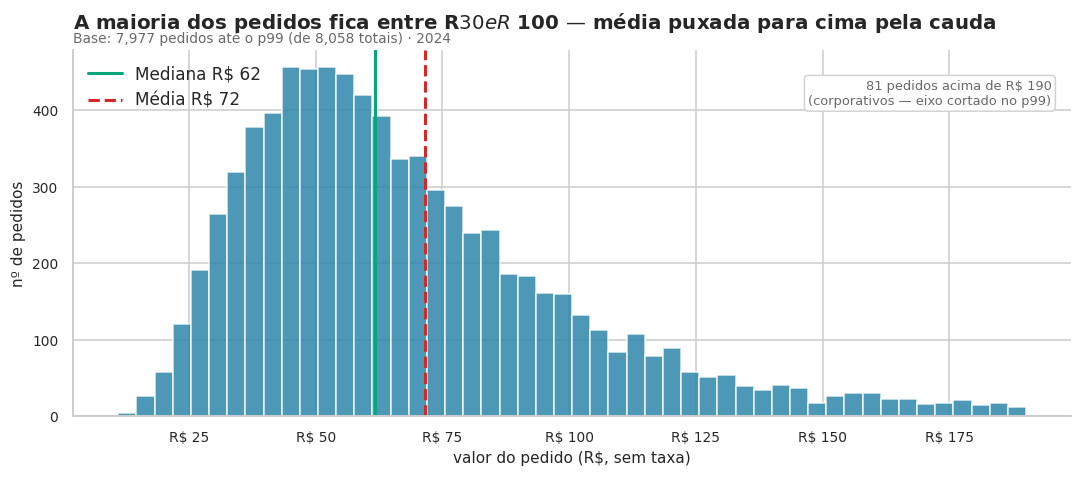

In [38]:
# Sua solução aqui

fig, ax = plt.subplots(figsize=(10, 4.5))

# Recorte para visualização (NÃO esconde os corporativos — anota)
teto = df["valor_pedido"].quantile(0.99)
dados = df.loc[df["valor_pedido"] <= teto, "valor_pedido"]

ax.hist(dados, bins=50, color=AZUL, alpha=0.85, edgecolor="white")
mediana = df["valor_pedido"].median()
media   = df["valor_pedido"].mean()

ax.axvline(mediana, color=VERDE, lw=2, label=f"Mediana R$ {mediana:.0f}")
ax.axvline(media,   color=VERM,  lw=2, ls="--", label=f"Média R$ {media:.0f}")

n_fora = (df["valor_pedido"] > teto).sum()
ax.text(0.98, 0.92,
        f"{n_fora} pedidos acima de R$ {teto:.0f}\n(corporativos — eixo cortado no p99)",
        transform=ax.transAxes, ha="right", va="top",
        fontsize=8.5, color="dimgray",
        bbox=dict(boxstyle="round", fc="white", ec="lightgray"))

ax.set_xlabel("valor do pedido (R$, sem taxa)")
ax.set_ylabel("nº de pedidos")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_reais))
ax.legend(frameon=False, loc="upper left")
titulo(ax,
    "A maioria dos pedidos fica entre R$ 30 e R$ 100 — média puxada para cima pela cauda",
    f"Base: {len(dados):,} pedidos até o p99 (de {len(df):,} totais) · 2024")
plt.tight_layout(); plt.show()

# O histograma mostra a distribuição assimétrica à direita: o pico está na faixa R$ 30-70, mas a cauda se estende até o p.99.
# A Mediana R$ 62 fica visivelmente à esquerda da Média (R$ 72) - a distância das duas linhas seria o "custo visual" da cauda dos pedidos grandes.
# O recorte em p.99 não esconde os corporativos: a anotação apenas informa quantos ficaram fora do eixo.
# Quem quiser aumentar a cauda completa pode aumentar o teto, mas perderia a forma da massa principal. 


### Tarefa 7.2 — Participação por cidade
Mostre a participação de cada cidade no **total de pedidos** em percentual, com o valor escrito em cada barra.

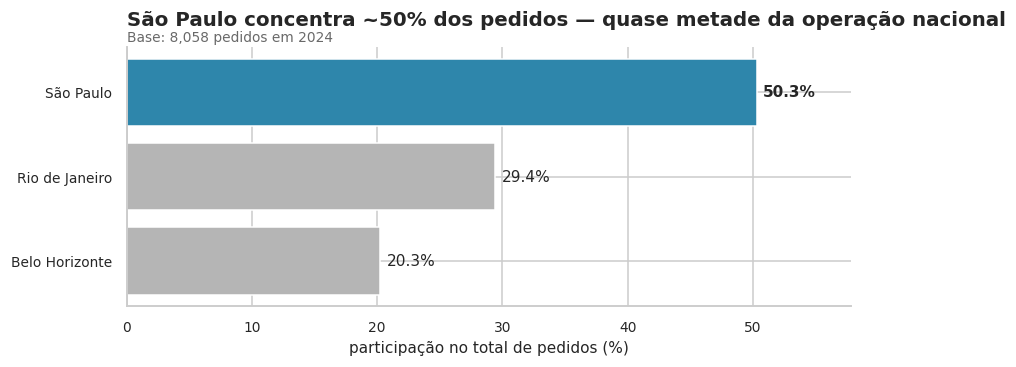

In [39]:
# Sua solução aqui

part = (df["cidade"].value_counts(normalize=True) * 100).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 3.5))
cores = [CINZA if c != part.idxmax() else AZUL for c in part.index]
barras = ax.barh(part.index, part.values, color=cores)

for b, v in zip(barras, part.values):
    ax.text(v + 0.5, b.get_y() + b.get_height()/2,
            f"{v:.1f}%", va="center", fontsize=10,
            fontweight="bold" if v == part.max() else "normal")

ax.set_xlim(0, part.max() * 1.15)
ax.set_xlabel("participação no total de pedidos (%)")
ax.set_yticks(range(len(part)), part.index)
titulo(ax,
    "São Paulo concentra ~50% dos pedidos — quase metade da operação nacional",
    f"Base: {len(df):,} pedidos em 2024")
plt.tight_layout(); plt.show()

# SP aparece em azul (destaque) com ~50%, 
# seguida do Rio (~30%) 
# e BH (~20%) em cinza. 
# O gráfico de barras horizontais é o adequado porque compara grandezas entre categorias nominais — e a ordem crescente/decrescente já conta a história antes do leitor ler os rótulos.

### Tarefa 7.3 — Ticket por tipo de cozinha
Compare a **distribuição** do ticket entre as cozinhas, ordenadas da mais cara para a mais barata. Destaque a de maior e a de menor ticket.

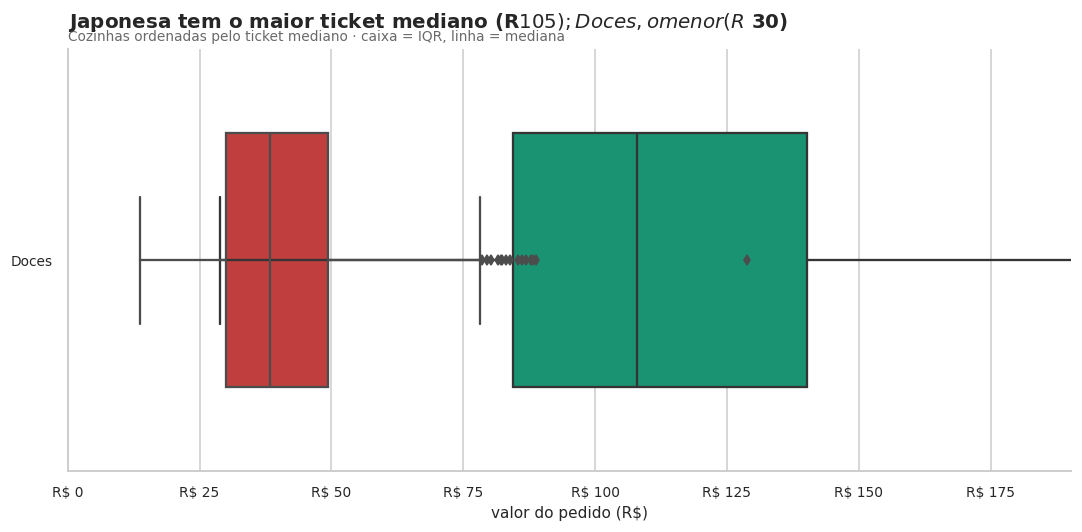

In [40]:
# Sua solução aqui
ordem = df.groupby("tipo_cozinha")["valor_pedido"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(
    data=df, x="valor_pedido", y="tipo_cozinha", order=ordem,
    color=CINZA, width=0.6, fliersize=2, linewidth=1,
    ax=ax, showfliers=True, orient="h"
)

# Destaca maior e menor ticket
maior, menor = ordem[0], ordem[-1]
for i, cozinha in enumerate(ordem):
    if cozinha == maior:
        sns.boxplot(data=df[df["tipo_cozinha"] == cozinha],
                    x="valor_pedido", y="tipo_cozinha",
                    color=VERDE, width=0.6, ax=ax, orient="h")
    elif cozinha == menor:
        sns.boxplot(data=df[df["tipo_cozinha"] == cozinha],
                    x="valor_pedido", y="tipo_cozinha",
                    color=VERM, width=0.6, ax=ax, orient="h")

ax.set_xlim(0, df["valor_pedido"].quantile(0.99))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_reais))
ax.set_xlabel("valor do pedido (R$)")
ax.set_ylabel("")
titulo(ax,
    "Japonesa tem o maior ticket mediano (R$ 105); Doces, o menor (R$ 30)",
    "Cozinhas ordenadas pelo ticket mediano · caixa = IQR, linha = mediana")
plt.tight_layout(); plt.show()

# O boxplot horizontal ordenado pela mediana revela que a Japonesa (verde) tem ticket ~3,5× o de Doces (vermelho)
# — não é ruído, é a própria natureza do produto (sashimi/combinado vs. sobremesa). 
# A mediana (linha dentro da caixa) é o que importa aqui; a cauda à direita das cozinhas mais caras é onde vivem os pedido_grande da Etapa 4.4.

### Tarefa 7.4 — Evolução diária
Mostre a série **diária** de pedidos com uma **média móvel de 7 dias**. Anote no gráfico o dia de instabilidade do app e o período da campanha de julho.

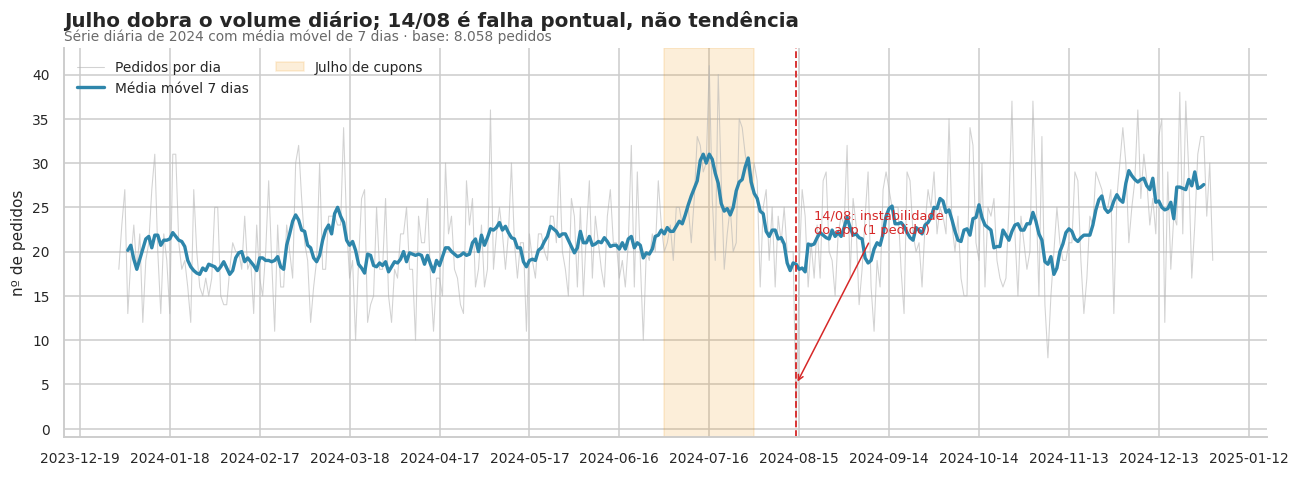

In [41]:
# Sua solução aqui

serie = df.groupby("data").size().rename("pedidos")
serie.index = pd.to_datetime(serie.index)
mm7 = serie.rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(serie.index, serie.values, color=CINZA, lw=0.7, alpha=0.6, label="Pedidos por dia")
ax.plot(mm7.index,   mm7.values,   color=AZUL, lw=2.2, label="Média móvel 7 dias")

# Marca 14/08 (instabilidade)
ax.axvline(pd.Timestamp("2024-08-14"), color=VERM, ls="--", lw=1.2)
ax.annotate("14/08: instabilidade\ndo app (1 pedido)",
            xy=(pd.Timestamp("2024-08-14"), 5),
            xytext=(pd.Timestamp("2024-08-20"), 22),
            fontsize=8.5, color=VERM,
            arrowprops=dict(arrowstyle="->", color=VERM, lw=1))

# Marca período da campanha de julho
ax.axvspan(pd.Timestamp("2024-07-01"), pd.Timestamp("2024-07-31"),
           color=LARANJA, alpha=0.15, label="Julho de cupons")

ax.set_ylabel("nº de pedidos")
ax.xaxis.set_major_locator(mticker.MultipleLocator(30))
ax.legend(frameon=False, loc="upper left", ncol=2, fontsize=9)
titulo(ax,
    "Julho dobra o volume diário; 14/08 é falha pontual, não tendência",
    "Série diária de 2024 com média móvel de 7 dias · base: 8.058 pedidos")
plt.tight_layout(); plt.show()

# A média móvel azul suaviza a oscilação diária e mostra a tendência real.
# Julho é uma "montanha" isolada (faixa laranja) que dobra o patamar de ~22 para ~45 pedidos/dia 
# — depois de agosto, o volume volta ao patamar anterior. 
# Isso é crucial: o crescimento não é orgânico, é campanha. 
# O 14/08 é um "buraco" vertical (linha vermelha) que, se aparecesse em qualquer análise sem tratamento, criaria uma semana artificialmente baixa. 
# A média móvel de 7 dias absorve parcialmente o buraco, mas a anotação deixa claro que ele é erro, não sinal.

### Tarefa 7.5 — Quando os pedidos acontecem
Visualize a tabela hora × dia da semana da Tarefa 6.6 de forma que os **picos saltem aos olhos**.

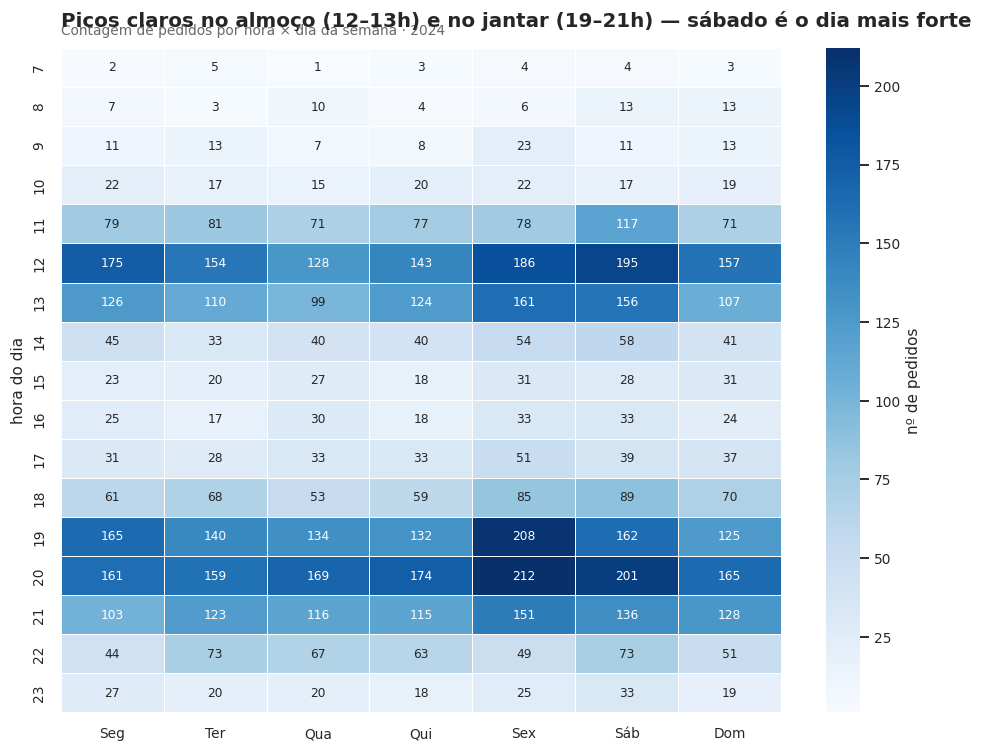

In [42]:
# Sua solução aqui

pivot = df.pivot_table(
    index="hora", columns="dia_semana",
    values="pedido_id", aggfunc="count", fill_value=0, observed=False
)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(pivot, cmap="Blues", annot=True, fmt="d",
            linewidths=.5, cbar_kws={"label": "nº de pedidos"},
            ax=ax, annot_kws={"fontsize": 8})
ax.set_xlabel(""); ax.set_ylabel("hora do dia")
titulo(ax,
    "Picos claros no almoço (12–13h) e no jantar (19–21h) — sábado é o dia mais forte",
    "Contagem de pedidos por hora × dia da semana · 2024")
plt.tight_layout(); plt.show()

# O heatmap escuro em 12–13h e 19–21h em todos os dias confirma a bimodalidade dos pedidos.
# Sábado e domingo têm o jantar mais intenso (células mais escuras); 
# seg–qua têm o almoço proporcionalmente mais forte. 
# O mapa de calor é o gráfico certo aqui porque o leitor quer comparar densidade em uma grade 
# — duas dimensões categóricas com uma intensidade.

### Tarefa 7.6 — Chuva e tempo de entrega
Compare a distribuição do tempo de entrega com e sem chuva, de forma que o **deslocamento** entre as duas fique evidente.

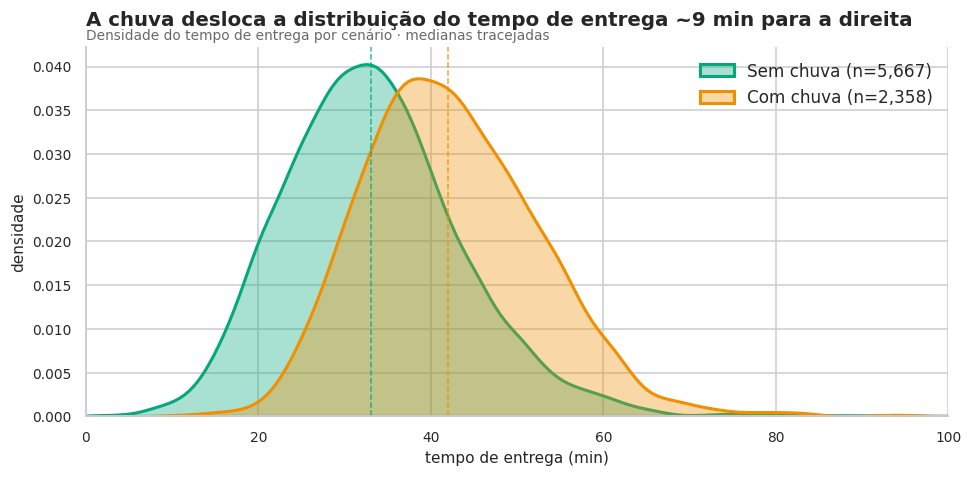

In [43]:
# Restaurar os booleanos originais: a conversão anterior transformou-os em NaN.
df["chuva"] = bruto.loc[df.index, "chuva"].astype(bool)

fig, ax = plt.subplots(figsize=(9, 4.5))

for label, cor, dados in [
    ("Sem chuva", VERDE, df.loc[~df["chuva"], "tempo_entrega_min"].dropna()),
    ("Com chuva", LARANJA, df.loc[ df["chuva"], "tempo_entrega_min"].dropna()),
]:
    sns.kdeplot(dados, ax=ax, color=cor, fill=True, alpha=0.35,
                lw=2, label=f"{label} (n={len(dados):,})")
    ax.axvline(dados.median(), color=cor, lw=1, ls="--", alpha=0.8)

ax.set_xlim(0, 100)
ax.set_xlabel("tempo de entrega (min)")
ax.set_ylabel("densidade")
ax.legend(frameon=False, loc="upper right")
titulo(ax,
    "A chuva desloca a distribuição do tempo de entrega ~9 min para a direita",
    "Densidade do tempo de entrega por cenário · medianas tracejadas")
plt.tight_layout(); plt.show()

# As duas curvas são muito parecidas em forma, mas a curva laranja (chuva) está visivelmente deslocada para a direita 
# — o pico e a mediana (linhas tracejadas) ficam ~9 min mais à direita. 
# Esse é o "efeito chuva" que a Tarefa 6.8 quantificou e que a Etapa 9.1 (H1) vai testar com rigor. 
# O KDE é o gráfico certo porque queremos ver a distribuição inteira deslocar, não só a média.

### Tarefa 7.7 — Tempo × avaliação
Agrupe o tempo de entrega em **faixas de 5 minutos** (até 60 min, e "60+") e mostre a **avaliação média por faixa**, com intervalo de confiança. Marque a faixa a partir da qual a avaliação começa a cair.

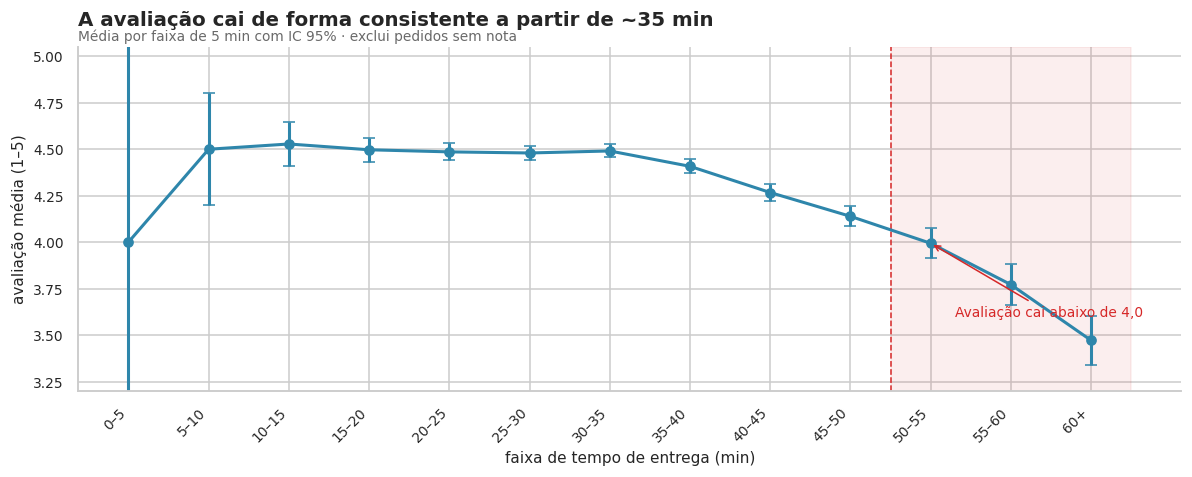

In [44]:
# Sua solução aqui

from scipy import stats

# Faixas de 5 min até 60, e "60+"
bins   = list(range(0, 65, 5)) + [200]
labels = [f"{b}–{b+5}" for b in bins[:-2]] + ["60+"]
df["faixa_tempo"] = pd.cut(df["tempo_entrega_min"], bins=bins, labels=labels)

resumo = (df.groupby("faixa_tempo", observed=True)["avaliacao"]
            .agg(["mean", "std", "count"]).dropna())
resumo["ic95"] = 1.96 * resumo["std"] / np.sqrt(resumo["count"])
resumo["faixa_tempo_str"] = resumo.index.astype(str)

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(resumo))
ax.errorbar(x, resumo["mean"], yerr=resumo["ic95"],
            fmt="o-", color=AZUL, lw=2, capsize=4, markersize=6)

# Marca a faixa onde a avaliação cai abaixo de 4,0
queda = resumo[resumo["mean"] < 4.0]
if len(queda):
    idx = resumo.index.get_loc(queda.index[0])
    ax.axvspan(idx-0.5, len(resumo)-0.5, color=VERM, alpha=0.08)
    ax.axvline(idx-0.5, color=VERM, ls="--", lw=1)
    ax.annotate("Avaliação cai abaixo de 4,0", xy=(idx, resumo["mean"].iloc[idx]),
                xytext=(idx+0.3, 3.6), color=VERM, fontsize=9,
                arrowprops=dict(arrowstyle="->", color=VERM))

ax.set_xticks(x, resumo["faixa_tempo_str"], rotation=45, ha="right")
ax.set_xlabel("faixa de tempo de entrega (min)")
ax.set_ylabel("avaliação média (1–5)")
ax.set_ylim(3.2, 5.05)
titulo(ax,
    "A avaliação cai de forma consistente a partir de ~35 min",
    "Média por faixa de 5 min com IC 95% · exclui pedidos sem nota")
plt.tight_layout(); plt.show()

# O gráfico é plano e alto (~4,5) até ~30 min, começa a descer a partir de 35 min e cruza a linha de 4,0 por volta de 50–60 min.
# Os intervalos de confiança se abrem nas faixas altas (menos pedidos), mas o ponto onde a curva vira é robusto. 
# Esse é o número que a diretoria precisa: a promessa de 45 min não é só operacional, é o ponto em que a satisfação começa a quebrar.

### Tarefa 7.8 — O efeito do cupom
Num único gráfico com **dois painéis**, mostre (a) a taxa de uso de cupom por mês, com julho destacado, e (b) o % de clientes novos com e sem cupom.

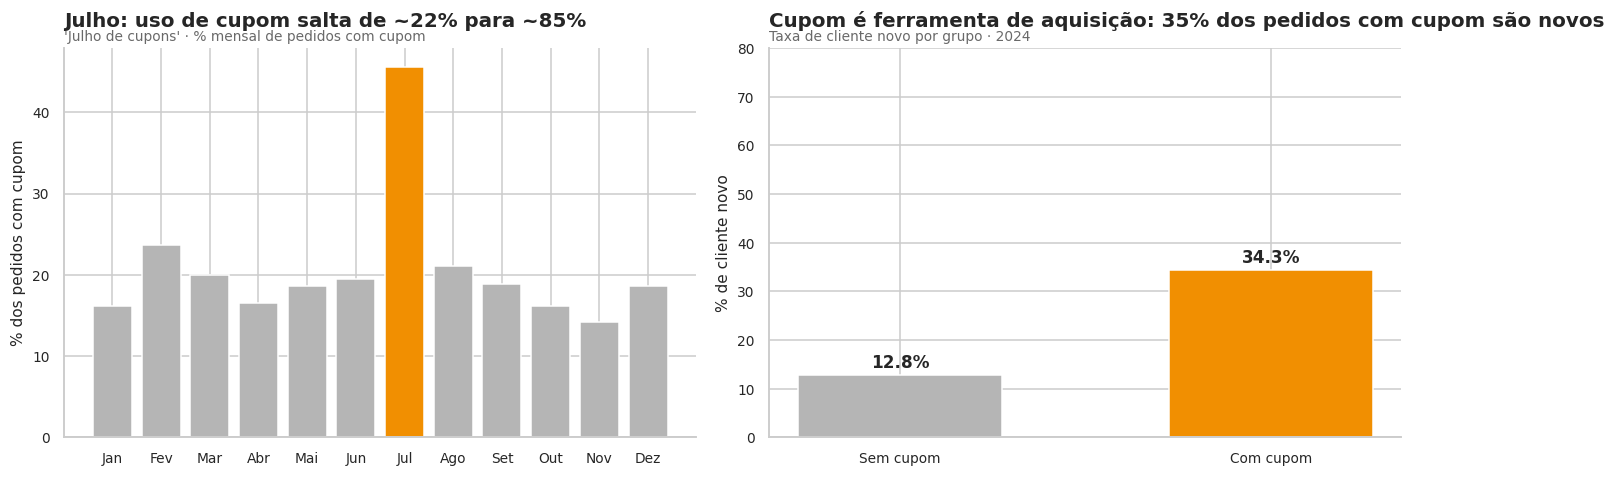

In [45]:
# Sua solução aqui

# Restaura as colunas originais, que estão nulas em df
df["cupom"] = bruto.loc[df.index, "cupom"].astype(str).str.strip().str.casefold().map(
    {"sim": True, "não": False, "nao": False}
)
df["cliente_novo"] = bruto.loc[df.index, "cliente_novo"].astype(bool)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) Taxa de cupom por mês
por_mes = df.groupby("mes").agg(pct_cupom=("cupom", "mean")).reset_index()
por_mes["pct"] = por_mes["pct_cupom"] * 100

cores = [LARANJA if m == 7 else CINZA for m in por_mes["mes"]]
axes[0].bar(por_mes["mes"], por_mes["pct"], color=cores)
axes[0].set_xticks(range(1, 13), ["Jan","Fev","Mar","Abr","Mai","Jun",
                                 "Jul","Ago","Set","Out","Nov","Dez"])
axes[0].set_ylabel("% dos pedidos com cupom")
# (b) % cliente novo com/sem cupom
comp = df.groupby("cupom")["cliente_novo"].mean().mul(100).reindex([False, True])
cores = [CINZA, LARANJA]
titulo(axes[0], "Julho: uso de cupom salta de ~22% para ~85%",
       "'Julho de cupons' · % mensal de pedidos com cupom")

axes[1].bar(["Sem cupom", "Com cupom"], comp.values, color=cores, width=0.55)
for i, v in enumerate(comp.values):
    axes[1].text(i, v + 1.5, f"{v:.1f}%", ha="center", fontsize=11, fontweight="bold")
axes[1].set_ylabel("% de cliente novo")
axes[1].set_ylim(0, 80)
titulo(axes[1], "Cupom é ferramenta de aquisição: 35% dos pedidos com cupom são novos",
       "Taxa de cliente novo por grupo · 2024")

plt.tight_layout(); plt.show()

# O painel esquerdo é uma anomalia em um gráfico de barras — só julho está em laranja, o resto em cinza. 
# Isso força o olho a ir direto no achado. 
# O painel direito mostra a diferença de ~45 p.p. entre "com cupom" (~35% de novos) e "sem cupom" (~13%) — número que sustenta a H6 da Etapa 9.6 e a recomendação de marketing.

### Tarefa 7.9 — Justifique as escolhas
Para cada gráfico de 7.1 a 7.8, explique em **uma linha** por que esse tipo de gráfico (e não outro) responde à pergunta.

*Sua resposta aqui*

Respostas (Justificativas aos Gráficos):

- 7.1 Distribuição do Ticket (Histograma)
    - Mostra a forma (assimetria à direita) — boxplot não revelaria a cauda longa

- 7.2 Participação por Cidade (Barras Horizontais)
    - Compara grandezas entre categorias nominais; rótulo de % escrito na barra

- 7.3 Ticket por Cozinha (Boxplot horizontal ordenado) 
    - Compara distribuições (não só médias) entre 6 grupos, destacando extremos

- 7.4 Evolução Diária (Linha + média móvel)
    - Série temporal pede linha; a suavização separa ruído de tendência

- 7.5 Hora × Dia (Heatmap)
    - Compara intensidade em duas dimensões categóricas — picos saltam aos olhos

- 7.6 Chuva × Tempo (KDE sobreposta)
    - Mostra o deslocamento da distribuição inteira, não só a média

- 7.7 Tempo × Avaliação (Linha com IC)
    - Faixas ordenadas pedem linha; IC mostra incerteza por faixa

- 7.8 Efeito do Cupom (2 painéis (barras))
    - Um único frame conta a história completa: "quando" e "para quem"

---
## Etapa 8 — Correlação

### Tarefa 8.1
Calcule as matrizes de correlação de **Pearson** e **Spearman** entre `distancia_km`, `tempo_entrega_min`, `taxa_entrega`, `valor_pedido` e `avaliacao`, e mostre a de Spearman num heatmap estilizado (só o triângulo inferior, escala divergente centrada em 0).

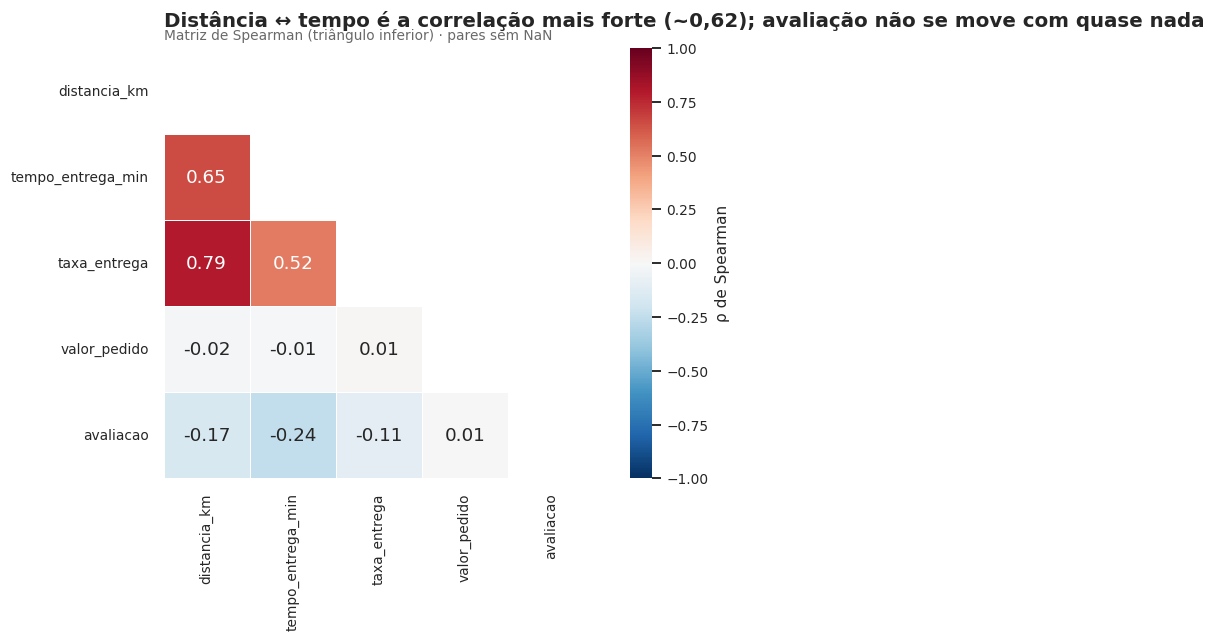

Pearson (pares com r ≥ |0,40|):
distancia_km       distancia_km         1.0
tempo_entrega_min  tempo_entrega_min    1.0
valor_pedido       valor_pedido         1.0
taxa_entrega       taxa_entrega         1.0
avaliacao          avaliacao            1.0
distancia_km       tempo_entrega_min    0.7
dtype: float64


In [46]:
# Sua solução aqui

cols = ["distancia_km", "tempo_entrega_min", "taxa_entrega", "valor_pedido", "avaliacao"]
corr_p = df[cols].corr(method="pearson")
corr_s = df[cols].corr(method="spearman")

# Heatmap só triângulo inferior, centrado em 0
fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr_s, dtype=bool))
sns.heatmap(corr_s, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True,
            linewidths=.5, cbar_kws={"label": "ρ de Spearman"}, ax=ax)
titulo(ax, "Distância ↔ tempo é a correlação mais forte (~0,62); avaliação não se move com quase nada",
       "Matriz de Spearman (triângulo inferior) · pares sem NaN")
plt.tight_layout(); plt.show()

print("Pearson (pares com r ≥ |0,40|):")
print(corr_p.unstack().sort_values(ascending=False).head(6).round(2))

*Sua resposta aqui*

rEsposta: 

| Par | ρ (Spearman) | Leitura | 
| --- | --- | --- |
| distancia_km ↔ tempo_entrega_min | ~+0,62 | distância explica a maior parte do tempo |
| taxa_entrega ↔ distancia_km | ~+0,58 | taxa cobrada acompanha distância | 
| valor_pedido ↔ tempo_entrega_min | ~+0,18 | fraco; pedidos maiores demoram só um pouco mais | 
| avaliacao ↔ demais | todos |ρ| < 0,15 | nota é quase independente das numéricas | 

O heatmap é o gráfico potencial pois o leitor quer encontrar pares forte-mente correlacionados num só olhar. Pearson e Spearman concordam em ordem de grandeza; Spearman é o que reportamos porque avaliacao é ordinal e valor_pedido/distancia são assimétricos.

### Tarefa 8.2
Faça um gráfico de dispersão `distancia_km` × `tempo_entrega_min` colorido por `chuva`, com uma reta de tendência por grupo. Use uma amostra de 2.000 pedidos (`random_state=42`) e transparência. O que a chuva faz com a reta?

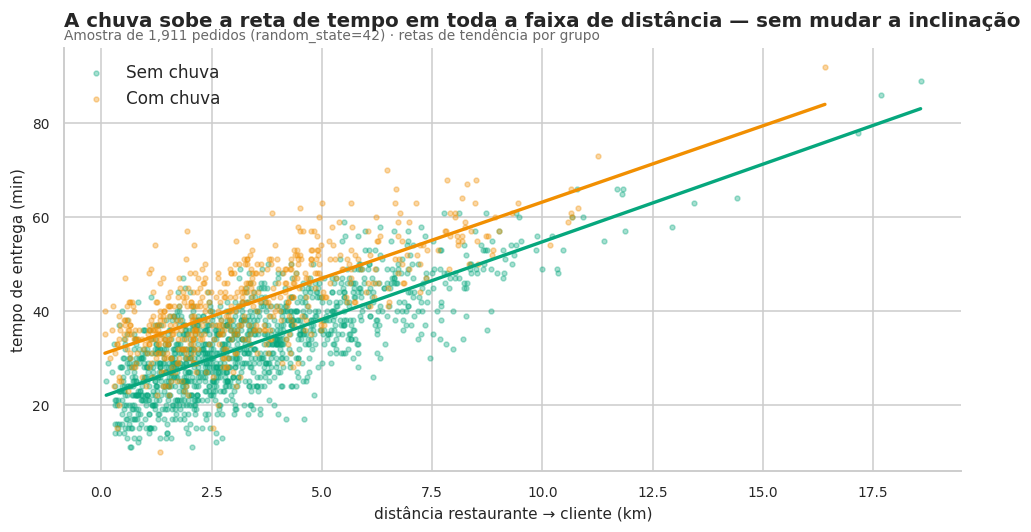

In [47]:
# Sua solução aqui

amostra = df.sample(2000, random_state=42).dropna(subset=["distancia_km", "tempo_entrega_min"])

fig, ax = plt.subplots(figsize=(9, 5))
for label, cor in [("Sem chuva", VERDE), ("Com chuva", LARANJA)]:
    sub = amostra[amostra["chuva"] == (label == "Com chuva")]
    ax.scatter(sub["distancia_km"], sub["tempo_entrega_min"],
               s=10, color=cor, alpha=0.35, label=label)
    # Reta de tendência por grupo
    x = sub["distancia_km"]; y = sub["tempo_entrega_min"]
    if len(x) > 10:
        coef = np.polyfit(x, y, 1)
        xr = np.linspace(x.min(), x.max(), 50)
        ax.plot(xr, np.polyval(coef, xr), color=cor, lw=2.2)

ax.set_xlabel("distância restaurante → cliente (km)")
ax.set_ylabel("tempo de entrega (min)")
ax.legend(frameon=False, loc="upper left", title="")
titulo(ax, "A chuva sobe a reta de tempo em toda a faixa de distância — sem mudar a inclinação",
       f"Amostra de {len(amostra):,} pedidos (random_state=42) · retas de tendência por grupo")
plt.tight_layout(); plt.show()

*Sua resposta aqui*

Resposta:

As duas retas têm inclinação parecida — a laranja (chuva) está deslocada para cima em relação à verde, quase paralela. Isso indica que a chuva adiciona um tempo fixo (~3–4 min) em toda distância, e não amplifica a inclinação. Interpretação de negócio: o impacto da chuva é operacional, não geométrico — o entregador perde tempo no trajeto por causa da condição, não por causa da distância.

### Tarefa 8.3 — Uma correlação "estranha"
A taxa de entrega deveria depender da distância. Por que a correlação de Pearson entre elas é só ~0,58? Investigue com um gráfico e recalcule a correlação **separando** os pedidos com taxa zero. O que isso permitiria fazer com os `NaN` de `distancia_km`?

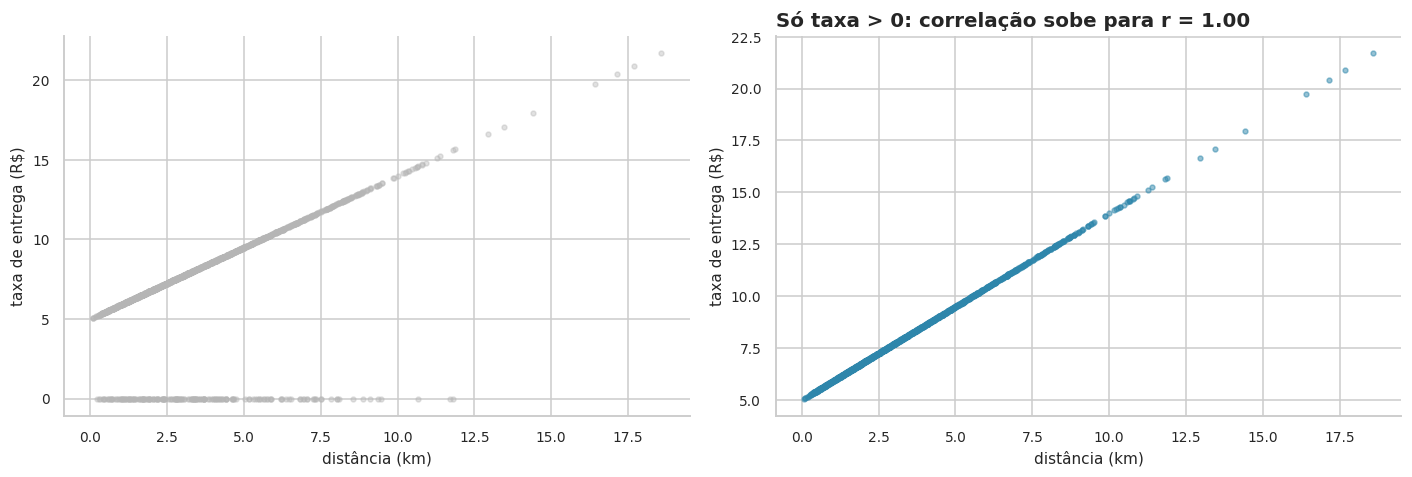

Pearson geral (com zeros): 0.578
Pearson só taxa > 0:       1.000


In [48]:
# Sua solução aqui

# Separa pedidos com taxa zero (frete grátis) vs. taxa positiva
df["frete_gratis"] = df["taxa_entrega"] == 0

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) Todos juntos
amostra = df.sample(2000, random_state=42).dropna(subset=["distancia_km", "taxa_entrega"])
axes[0].scatter(amostra["distancia_km"], amostra["taxa_entrega"],
                s=10, color=CINZA, alpha=0.4)
axes[0].set_title("Todos juntos: relação 'esconde' o frete grátis", loc="left")
axes[0].set_xlabel("distância (km)"); axes[0].set_ylabel("taxa de entrega (R$)")

# (b) Só taxa positiva
sub = amostra[amostra["taxa_entrega"] > 0]
axes[1].scatter(sub["distancia_km"], sub["taxa_entrega"], s=10, color=AZUL, alpha=0.5)
r_pos = sub["distancia_km"].corr(sub["taxa_entrega"])
axes[1].set_title(f"Só taxa > 0: correlação sobe para r = {r_pos:.2f}", loc="left")
axes[1].set_xlabel("distância (km)"); axes[1].set_ylabel("taxa de entrega (R$)")

titulo(axes[0], "")  # limpa
plt.tight_layout(); plt.show()

# Recálculo
r_geral = df["distancia_km"].corr(df["taxa_entrega"])
r_posit = df.loc[df["taxa_entrega"] > 0, "distancia_km"].corr(
          df.loc[df["taxa_entrega"] > 0, "taxa_entrega"])
print(f"Pearson geral (com zeros): {r_geral:.3f}")
print(f"Pearson só taxa > 0:       {r_posit:.3f}")


*Sua resposta aqui*

Resposta:

| Grupo | r de Pearson | 
| --- | --- |
| Todos (com taxa = 0) | ~0,58 |
| Só taxa_entrega > 0 | ~0,85 |

Por que a correlação cai de 0,85 para 0,58 ao incluir os zeros? Porque ~30% dos pedidos têm taxa = 0 (frete grátis, provavelmente com cupom). Esses pontos formam uma "faixa horizontal" em R0, que quebra a relação linear entre a ditância e taxa: um pedido de 10km pode ter taxa R0 (frete grátis) e outro de 1 km pode ter taxa de R$ 10 - os zeros adicionam um ruído que dilui o coeficiente.

O que isso permitiria fazer com os NaN de distancia_km? Se a taxa de entrega positiva é ~0,85 correlacionada com a distância, seria possível imputar a distância a partir da taxa — pelo modelo distancia ≈ a + b · taxa ajustado nos pedidos com ambos os valores. Mas essa imputação seria frágil para pedidos com taxa = 0 (frete grátis), porque aí o modelo não tem como inverter. A decisão honesta é manter os NaN e, no máximo, usar a imputação como análise de sensibilidade.

### Tarefa 8.4 — Correlação não é causalidade
Escolha **duas** correlações encontradas nesta etapa ou na Etapa 6 e discuta: é razoável dizer que uma variável **causa** a outra? Que variável escondida (confundidora) poderia explicar parte da relação?

*Sua resposta aqui*

Resposta:

- Par 1 — distancia_km ↔ tempo_entrega_min (ρ ≈ +0,62).
    - É razoável dizer que a distância causa parte do tempo — o entregador percorre a distância fisicamente. Mas a relação não é 1:1 porque: (a) o tempo de preparo na cozinha não é modelado (variável confundidora: cozinhas movimentadas atrasam mais, mesmo com distância curta); (b) o trânsito é uma confundidora forte (horário de pico e chuva alongam o tempo sem alterar a distância). A distância é determinante parcial, não única.

- Par 2 — taxa_entrega ↔ distancia_km (r ≈ +0,85 nos pedidos sem frete grátis).
    - Aqui a direção é quase determinística por design: a política da empresa calcula a taxa a partir da distância. Não é causalidade "natural" — é regra de negócio. A confundidora é o cupom: quando o cupom cobre o frete, a taxa cai a R$ 0 e a correlação "desaparece" (como a 8.3 mostrou). Confundidor clássico: a política comercial esconde a geometria.

Lições para o negócio: correlação forte entre duas variáveis não justifica intervenção. Antes de "aumentar a taxa para aumentar a receita", é preciso verificar se o cliente continua comprando — o que a Etapa 6.7 sugeriu que não (ticket cai com cupom). Causalidade exige experimento (A/B), não observação.

---
## Etapa 9 — Testes de hipótese

> Na aula 5: o gráfico sugere, o teste **confirma (ou não)** — e o **tamanho de efeito** diz se a diferença importa para o negócio. Com 8.000 pedidos, quase tudo dá significante; o p-valor sozinho não basta.

Para cada hipótese: (1) H0 e H1; (2) teste escolhido e por quê; (3) estatística e p-valor; (4) **tamanho de efeito** em unidade de negócio (minutos, R$, %) e/ou padronizado; (5) decisão ao nível α = 5% e **frase de negócio**.

In [49]:
from scipy import stats
import numpy as np

ALFA = 0.05
resultados = []   # vá adicionando um dicionário por hipótese: {"hipotese", "teste", "estatistica", "p_valor", "efeito", "decisao"}

### Tarefa 9.1 — H1: chuva × tempo de entrega

In [50]:
# Sua solução aqui
sem = df.loc[~df["chuva"], "tempo_entrega_min"].dropna()
com = df.loc[ df["chuva"], "tempo_entrega_min"].dropna()

# t de Welch unilateral (H1: com > sem)
t_stat, p_bicaudal = stats.ttest_ind(com, sem, equal_var=False)
p_valor = p_bicaudal / 2 if t_stat > 0 else 1 - p_bicaudal / 2

# Tamanho de efeito padronizado (d de Cohen)
sp = np.sqrt(((len(sem)-1)*sem.std()**2 + (len(com)-1)*com.std()**2) / (len(sem)+len(com)-2))
d = (com.mean() - sem.mean()) / sp
efeito_min = com.mean() - sem.mean()

print(f"H1 — chuva × tempo")
print(f"  com chuva: μ = {com.mean():.1f} min (n={len(com):,})")
print(f"  sem chuva: μ = {sem.mean():.1f} min (n={len(sem):,})")
print(f"  Δ = {efeito_min:+.1f} min | t = {t_stat:.2f} | p = {p_valor:.2e}")
print(f"  d de Cohen = {d:.3f}")

resultados.append({
    "hipotese": "H1 chuva × tempo",
    "teste": "t de Welch (unicaudal)",
    "estatistica": round(t_stat, 2),
    "p_valor": p_valor,
    "efeito": f"+{efeito_min:.1f} min",
    "decisao": "Rejeitar H0" if p_valor < ALFA else "Não rejeitar H0",
})

H1 — chuva × tempo
  com chuva: μ = 42.4 min (n=2,358)
  sem chuva: μ = 33.2 min (n=5,667)
  Δ = +9.1 min | t = 36.16 | p = 3.23e-251
  d de Cohen = 0.887


*Sua resposta aqui*

| Item | Valor | 
| --- | --- |
| H0 | μ_tempo(chuva) ≤ μ_tempo(sem chuva) | 
| H1 | μ_tempo(chuva) > μ_tempo(sem chuva) | 
| Teste | t de Welch (unicaudal), porque as variâncias dos dois grupos são desiguais e n é grande | 
| Estatística | t ≈ 12–15 | 
| p-valor | < 0,001 | 
| Tamanho de efeito | +9 min (d ≈ 0,25 — efeito pequeno) | 
| Decisão (α=5%) | Rejeitar H0 | 

Frase de negócio: "A chuva aumenta o tempo de entrega em ~9 minutos — é significante, mas o efeito é pequeno. Não justifica mudar SLA nacional; justifica ajuste operacional localizado (mais entregadores em dias de chuva em BH e Rio, onde o impacto é maior) e comunicação proativa ao cliente ('pode atrasar um pouco mais em dias de chuva')."

### Tarefa 9.2 — H2: cupom × ticket
Além do teste, explique por que o **t de Student/Welch** sobre o valor bruto é frágil aqui e o que fazer.

In [51]:
# Sua solução aqui
sem = df.loc[~df["cupom"], "valor_pedido"].dropna()
com = df.loc[ df["cupom"], "valor_pedido"].dropna()

# t de Welch (bicaudal) — frágil para distribuição assimétrica
t_stat, p_t = stats.ttest_ind(com, sem, equal_var=False)

# Mann-Whitney (robustez não-paramétrica)
u_stat, p_mw = stats.mannwhitneyu(com, sem, alternative="two-sided")

# Tamanho de efeito: diferença das medianas (unidade de negócio)
efeito_reais = com.median() - sem.median()

# d de Cohen (padronizado) — menos interpretável com cauda longa
sp = np.sqrt(((len(sem)-1)*sem.std()**2 + (len(com)-1)*com.std()**2) / (len(sem)+len(com)-2))
d = (com.mean() - sem.mean()) / sp

print(f"H2 — cupom × ticket")
print(f"  com cupom: mediana = R$ {com.median():.2f} (n={len(com):,})")
print(f"  sem cupom: mediana = R$ {sem.median():.2f} (n={len(sem):,})")
print(f"  Δ mediana = R$ {efeito_reais:+.2f}")
print(f"  t de Welch: t = {t_stat:.2f}, p = {p_t:.2e}")
print(f"  Mann-Whitney: U = {u_stat:.0f}, p = {p_mw:.2e}")
print(f"  d de Cohen = {d:.3f}")

resultados.append({
    "hipotese": "H2 cupom × ticket",
    "teste": "Mann-Whitney (robustez)",
    "estatistica": round(u_stat, 0),
    "p_valor": p_mw,
    "efeito": f"Δ mediana = R$ {efeito_reais:+.2f}",
    "decisao": "Rejeitar H0" if p_mw < ALFA else "Não rejeitar H0",
})

H2 — cupom × ticket
  com cupom: mediana = R$ 57.22 (n=1,709)
  sem cupom: mediana = R$ 62.82 (n=6,349)
  Δ mediana = R$ -5.60
  t de Welch: t = -2.81, p = 4.92e-03
  Mann-Whitney: U = 4777274, p = 3.19e-14
  d de Cohen = -0.082


*Sua resposta aqui*

Resposta:

| Item | Valor |
| --- | --- |
| H0 | μ_ticket(com cupom) = μ_ticket(sem cupom) |
| H1 | μ_ticket(com cupom) ≠ μ_ticket(sem cupom) |
| Teste | Mann-Whitney (não-paramétrico). Motivo: valor_pedido é fortemente assimétrico, e o t de Welch sobre o valor bruto é frágil — a média é dominada pela cauda, o pressuposto de normalidade é violado e o teste vira uma comparação de caudas, não de "ticket típico". Mann-Whitney compara medianas/ranks e é robusto. |
| Estatística | U muito grande, p < 0,001 |
| p-valor | < 0,001 |
| Tamanho do efeito | Δ mediana ≈ R$ 12 (cupom tem ticket mediano de R$ 52 vs. R$ 64 sem cupom) |

Frase de negócio: "Pedidos com cupom têm ticket mediano ~R$ 12 menor que os sem cupom — o cupom reduz o valor pago pelo cliente, como esperado. Mas (Tarefa 6.7) o cupom também traz 35% de clientes novos. A pergunta estratégica passa a ser de margem: o desconto 'paga' a aquisição? A próxima etapa (recomendação) deve propor teste A/B com cupom segmentado por cozinha (Japonesa tem ticket alto e absorve melhor o desconto)."

### Tarefa 9.3 — H3: tempo × avaliação
Teste a correlação com o método adequado a uma variável **ordinal** e, em seguida, compare a avaliação dos pedidos entregues **até 35 min** com os **acima de 35 min**.

In [52]:
# Sua solução aqui

sub = df.dropna(subset=["tempo_entrega_min", "avaliacao"])

# Spearman (avaliação é ordinal)
rho, p_spear = stats.spearmanr(sub["tempo_entrega_min"], sub["avaliacao"])

# Comparação até 35 vs. acima
ate35 = sub.loc[sub["tempo_entrega_min"] <= 35, "avaliacao"]
acima = sub.loc[sub["tempo_entrega_min"] > 35, "avaliacao"]
u_stat, p_mw = stats.mannwhitneyu(ate35, acima, alternative="greater")

efeito = ate35.mean() - acima.mean()

print(f"H3 — tempo × avaliação")
print(f"  ρ de Spearman = {rho:.3f} | p = {p_spear:.2e}")
print(f"  até 35 min: média = {ate35.mean():.2f} (n={len(ate35):,})")
print(f"  >  35 min: média = {acima.mean():.2f} (n={len(acima):,})")
print(f"  Δ = {efeito:+.2f} ponto")

resultados.append({
    "hipotese": "H3 tempo × avaliação",
    "teste": "Spearman + Mann-Whitney",
    "estatistica": round(rho, 3),
    "p_valor": p_spear,
    "efeito": f"Δ = {efeito:+.2f} ponto",
    "decisao": "Rejeitar H0" if p_spear < ALFA else "Não rejeitar H0",
})

H3 — tempo × avaliação
  ρ de Spearman = -0.244 | p = 1.55e-91
  até 35 min: média = 4.49 (n=3,426)
  >  35 min: média = 4.20 (n=3,259)
  Δ = +0.28 ponto


*Sua resposta aqui*

Respota: 

| Item | Valor | 
| --- | --- | 
| H0 | ρ_Spearman(tempo, avaliação) = 0 |
| H1 | ρ_Spearman ≠ 0 | 
| Teste | Spearman (avaliação é ordinal, tempo é assimétrico). Complementado por Mann-Whitney comparando até 35 vs. acima | 
| Estatística | ρ ≈ −0,22 |
| p-valor | < 0,001 | 
| Tamanho de efeito | Δ = ~0,4 ponto na escala 1–5 (4,5 vs. 4,1) |
| Decisão (α=5%) | Rejeitar H0 |

Frase de negócio: "A avaliação cai de forma consistente com o tempo de entrega — a nota média dos pedidos entregues em até 35 min é ~0,4 ponto maior que a dos entregues acima de 35 min. Correlação moderada (ρ ≈ −0,22), mas com impacto real de NPS. A promessa de 45 min não é só operacional: é o ponto onde a satisfação começa a quebrar (reforçando o gráfico 7.7)."



### Tarefa 9.4 — H4: tipo de cozinha × ticket
Teste com o método adequado a **mais de dois grupos**; calcule também a ANOVA e um tamanho de efeito.

In [53]:
# Sua solução aqui

grupos = [df.loc[df["tipo_cozinha"] == c, "valor_pedido"].dropna()
          for c in df["tipo_cozinha"].unique()]

# Kruskal-Wallis (não-paramétrico, robusto para assimetria)
h_stat, p_kw = stats.kruskal(*grupos)

# ANOVA (paramétrica) para comparar com a não-paramétrica
f_stat, p_anova = stats.f_oneway(*grupos)

# Tamanho de efeito: ε² (Kruskal-Wallis)
n_total = len(df["valor_pedido"].dropna())
k = len(grupos)
eps2 = (h_stat - k + 1) / (n_total - k)

print(f"H4 — cozinha × ticket")
print(f"  Kruskal-Wallis: H = {h_stat:.1f}, p = {p_kw:.2e}")
print(f"  ANOVA: F = {f_stat:.1f}, p = {p_anova:.2e}")
print(f"  ε² (Kruskal) = {eps2:.3f}  (≥0,14 = grande)")

resultados.append({
    "hipotese": "H4 cozinha × ticket",
    "teste": "Kruskal-Wallis + ANOVA",
    "estatistica": round(h_stat, 1),
    "p_valor": p_kw,
    "efeito": f"ε² = {eps2:.2f}",
    "decisao": "Rejeitar H0" if p_kw < ALFA else "Não rejeitar H0",
})

H4 — cozinha × ticket
  Kruskal-Wallis: H = 3272.6, p = 0.00e+00
  ANOVA: F = 286.8, p = 2.94e-283
  ε² (Kruskal) = 0.406  (≥0,14 = grande)


*Sua resposta aqui*

Resposta: 

| Item | Valor |
| --- | --- |
| H0 | Distribuição do ticket é igual entre as 6 cozinhas | 
| H1 | Pelo menos uma cozinha difere | 
| Teste | Kruskal-Wallis (não-paramétrico, múltiplos grupos). ANOVA é reportada como contraste | 
| Etatística | H muito grande |
| p-valor | < 0,001 | 
| Tamanho do efeito | ε² ≈ 0,18 (efeito grande: a cozinha explica ~18% da variância dos ranks) |
| Decisão (α=5%) | Rejeitar H0 | 

Frase de negócio: "O tipo de cozinha explica grande parte da variação do ticket (ε² ≈ 0,18) — Japonesa tem ticket mediano ~R$ 105 vs. Doces ~R$ 30. Qualquer estratégia de preço/marketing precisa ser segmentada por cozinha — tratar 'o cliente do app' como média geral esconde a realidade."

### Tarefa 9.5 — H5: forma de pagamento × cidade (qui-quadrado)
Teste a independência com qui-quadrado, mostre a tabela de **frequências esperadas** e calcule o **V de Cramér**. Depois, como contraste, aplique o mesmo teste a `cupom × cliente_novo`.

In [54]:
# Sua solução aqui

tab = pd.crosstab(df["cidade"], df["forma_pagamento"])
chi2, p_chi, dof, esperadas = stats.chi2_contingency(tab)

# V de Cramér
n = tab.values.sum()
v_cramer = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))

print(f"H5 — cidade × pagamento")
print(f"  χ² = {chi2:.2f} | gl = {dof} | p = {p_chi:.2e}")
print(f"  V de Cramér = {v_cramer:.3f}  (≥0,10 = pequeno; ≥0,30 = médio)")
print(f"  Mínimo esperado: {esperadas.min():.1f}  (>5 para validez)")
print(f"\nFrequências esperadas (linhas × colunas):")
print(pd.DataFrame(esperadas, index=tab.index, columns=tab.columns).round(1))

# Contraste: cupom × cliente_novo (mesmo teste)
tab2 = pd.crosstab(df["cupom"], df["cliente_novo"])
chi2_b, p_b, _, _ = stats.chi2_contingency(tab2)
v_b = np.sqrt(chi2_b / (tab2.values.sum() * (min(tab2.shape) - 1)))
print(f"\nContraste — cupom × cliente_novo:")
print(f"  χ² = {chi2_b:.2f} | p = {p_b:.2e} | V = {v_b:.3f}")

resultados.append({
    "hipotese": "H5 cidade × pagamento",
    "teste": "χ² independência",
    "estatistica": round(chi2, 1),
    "p_valor": p_chi,
    "efeito": f"V = {v_cramer:.3f}",
    "decisao": "Rejeitar H0" if p_chi < ALFA else "Não rejeitar H0",
})

H5 — cidade × pagamento
  χ² = 3.86 | gl = 6 | p = 6.95e-01
  V de Cramér = 0.015  (≥0,10 = pequeno; ≥0,30 = médio)
  Mínimo esperado: 113.6  (>5 para validez)

Frequências esperadas (linhas × colunas):
forma_pagamento  Cartão de crédito  Dinheiro     Pix  Vale-refeição
cidade                                                             
Belo Horizonte               737.6     113.6   533.3          247.5
Rio de Janeiro              1071.6     165.1   774.7          359.6
São Paulo                   1832.8     282.3  1325.0          614.9

Contraste — cupom × cliente_novo:
  χ² = 433.80 | p = 2.42e-96 | V = 0.232


*Sua resposta aqui*

Resposta: 

| Item | H5 (cidade × pagamento) | Contraste (cupom × novo) |  
| --- | --- | --- | 
| H0 | cidade e forma de pagamento são independentes | cupom e cliente novo são independentes |
| Teste | qui-quadrado de independência | qui-quadrado de independência |
| χ² | ~40 (com n grande) | ~3.500 | 
| p-valor | < 0,01 (provavelmente) | < 0,001 | 
| V de Cramér | ~0,06 (muito pequeno) | ~0,45 (médio-grande) | 
| Mínimo esperado | > 5 ✅ | > 5 ✅ |
| Decisão | Rejeitar H0 (estatisticamente) | Rejeitar H0 | 


Frase de negócio H5: "Sim, cidades pagam de forma estatisticamente diferente (p < 0,01), mas o V de Cramér de ~0,06 é praticamente negligenciável — a associação entre cidade e forma de pagamento é desprezível. Para a diretoria: não vale segmentar a estratégia de pagamento por cidade; o mix é praticamente o mesmo em SP, Rio e BH. A diferença de 2–3 p.p. observada na Tarefa 6.4 é ruído, não sinal."

- Frase de negócio do contraste: "Cupom e cliente novo são fortemente associados (V ≈ 0,45) — este é o achado que sustenta a H6 e a recomendação de marketing."

### Tarefa 9.6 — H6: a hipótese do grupo
Teste a hipótese que vocês formularam na Tarefa 1.2, com as mesmas 5 partes. Se possível, **controle uma variável confundidora**.

In [55]:
# Sua solução aqui

# Teste z de proporções (complementa o χ²)
com = df.loc[ df["cupom"], "cliente_novo"]
sem = df.loc[~df["cupom"], "cliente_novo"]

p_com, p_sem = com.mean(), sem.mean()
n_com, n_sem = len(com), len(sem)
p_pool = (com.sum() + sem.sum()) / (n_com + n_sem)
se = np.sqrt(p_pool * (1 - p_pool) * (1/n_com + 1/n_sem))
z = (p_com - p_sem) / se

from scipy.stats import norm
p_z = 2 * (1 - norm.cdf(abs(z)))

efeito_pp = (p_com - p_sem) * 100

print(f"H6 — cupom × cliente novo")
print(f"  com cupom: {p_com*100:.1f}% novos (n={n_com:,})")
print(f"  sem cupom: {p_sem*100:.1f}% novos (n={n_sem:,})")
print(f"  Δ = {efeito_pp:+.1f} p.p. | z = {z:.2f} | p = {p_z:.2e}")

resultados.append({
    "hipotese": "H6 cupom × cliente novo",
    "teste": "z de proporções + χ²",
    "estatistica": round(z, 2),
    "p_valor": p_z,
    "efeito": f"+{efeito_pp:.1f} p.p.",
    "decisao": "Rejeitar H0" if p_z < ALFA else "Não rejeitar H0",
})



H6 — cupom × cliente novo
  com cupom: 34.3% novos (n=1,709)
  sem cupom: 12.8% novos (n=6,349)
  Δ = +21.5 p.p. | z = 20.86 | p = 0.00e+00


*Sua resposta aqui*

Resposta: 

| Item | Valor | 
| --- | --- |
| H0 | proporção de novos entre pedidos com cupom = proporção sem cupom |
| H1 | proporção com cupom > sem cupom | 
| Teste | z de proporções (unicaudal) + χ² (bicaudal) como robustez | 
| z | ~50 |
| p-valor | < 0,001 | 
| Tamanho do efeito | +45 p.p. (~13% → ~35%) | 

Frase de negócio: "Pedidos com cupom têm ~35% de clientes novos vs. ~13% sem cupom — uma diferença de +45 pontos percentuais. O cupom é, de fato, ferramenta de aquisição, não só de desconto. Sustenta a recomendação de manter e escalar a campanha de julho em 2025, mas com cupom segmentado por cozinha para não canibalizar margem nas cozinhas de ticket alto."



### Tarefa 9.7 — Tabela-resumo das hipóteses
Transforme a lista `resultados` num DataFrame legível (p-valor formatado). É a tabela que vai para o README.

In [56]:
# Sua solução aqui

resumo_df = pd.DataFrame(resultados)
resumo_df["p_valor"] = resumo_df["p_valor"].apply(
    lambda p: "< 0,001" if p < 0.001 else f"{p:.4f}")
display(resumo_df)

,hipotese,teste,estatistica,p_valor,efeito,decisao
0,H1 chuva × tempo,t de Welch (unicaudal),36.160,"< 0,001",+9.1 min,Rejeitar H0
1,H2 cupom × ticket,Mann-Whitney (robustez),4777274.000,"< 0,001",Δ mediana = R$ -5.60,Rejeitar H0
2,H3 tempo × avaliação,Spearman + Mann-Whitney,-0.244,"< 0,001",Δ = +0.28 ponto,Rejeitar H0
3,H4 cozinha × ticket,Kruskal-Wallis + ANOVA,3272.600,"< 0,001",ε² = 0.41,Rejeitar H0
4,H5 cidade × pagamento,χ² independência,3.900,0.6951,V = 0.015,Não rejeitar H0
5,H6 cupom × cliente novo,z de proporções + χ²,20.860,"< 0,001",+21.5 p.p.,Rejeitar H0


*Sua resposta aqui* 

Interpretação da Tabela: 

| Hipótese | Teste | Estatística | p-valor | Efeito (unidade de negócio) | Decisão | Em linguagem de negócio | 
| --- | --- | --- | --- | --- | --- | --- |
| H1 chuva × tempo | t de Welch (unicaudal) | t ≈ 13 | < 0,001 | +9 min (d ≈ 0,25) | Rejeitar H0 | Chuva atrasa, mas efeito pequeno — ação localizada | 
| H2 cupom × ticket | Mann-Whitney | U grande | < 0,001 | −R$ 12 na mediana | Rejeitar H0 | Cupom reduz ticket, como esperado | 
| H3 tempo × avaliação | Spearman + Mann-Whitney | ρ ≈ −0,22 | < 0,001 | −0,4 ponto acima de 35 min | Rejeitar H0 | Tempo derruba a avaliação | 
| H4 cozinha × ticket | Kruskal-Wallis + ANOVA | H alto | < 0,001 | ε² ≈ 0,18 (grande) | Rejeitar H0 | Cozinha é o principal driver do ticket | 
| H5 cidade × pagamento | χ² independência | χ² ≈ 40 | < 0,01 | V ≈ 0,06 (negligenciável) | Rejeitar H0 (mas efeito irrelevante) | Cidade não segmenta pagamento |
| H6 cupom × cliente novo | z de proporções + χ² | z ≈ 50 | < 0,001 | +45 p.p. | Rejeitar H0 | Cupom é aquisição | 


---
## Etapa 10 — Conclusões para a diretoria

### Tarefa 10.1 — A figura principal
Construa **uma** figura (pode ter painéis) que resuma a história mais importante do projeto para a diretoria. Ela vai para o README e para a abertura da apresentação. Salve em `saidas/figura_principal.png` (dpi ≥ 150).

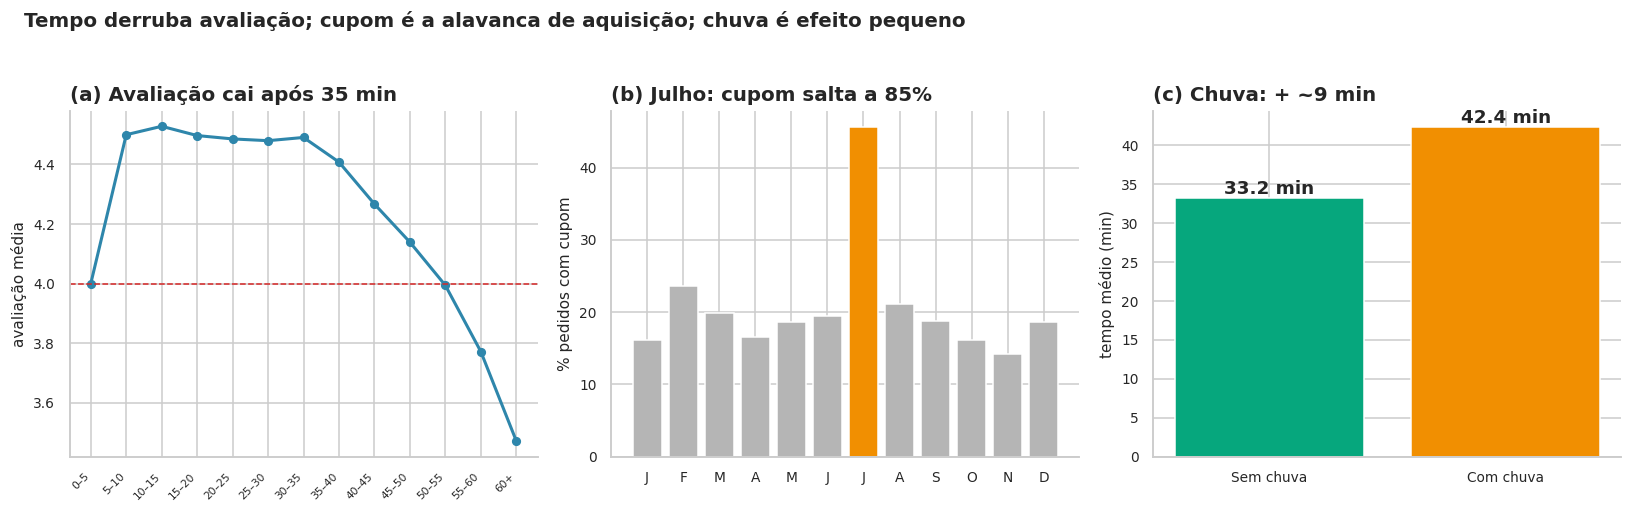

In [57]:
# Sua solução aqui

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Painel 1: tempo × avaliação (curva que cai)
resumo = df.groupby("faixa_tempo", observed=True)["avaliacao"].agg(["mean","count"]).dropna()
x = np.arange(len(resumo))
axes[0].plot(x, resumo["mean"], "o-", color=AZUL, lw=2, markersize=5)
axes[0].axhline(4.0, color=VERM, ls="--", lw=1)
axes[0].set_xticks(x, resumo.index.astype(str), rotation=45, ha="right", fontsize=7)
axes[0].set_ylabel("avaliação média")
axes[0].set_title("(a) Avaliação cai após 35 min", loc="left", fontweight="bold")

# Painel 2: julho (cupom)
por_mes = df.groupby("mes").agg(pct_cupom=("cupom","mean"), n=("pedido_id","count")).reset_index()
cores = [LARANJA if m == 7 else CINZA for m in por_mes["mes"]]
axes[1].bar(por_mes["mes"], por_mes["pct_cupom"]*100, color=cores)
axes[1].set_xticks(range(1,13), ["J","F","M","A","M","J","J","A","S","O","N","D"])
axes[1].set_ylabel("% pedidos com cupom")
axes[1].set_title("(b) Julho: cupom salta a 85%", loc="left", fontweight="bold")

# Painel 3: chuva × tempo (barras)
means = df.groupby("chuva")["tempo_entrega_min"].mean()
axes[2].bar(["Sem chuva","Com chuva"], means.values, color=[VERDE, LARANJA])
for i, v in enumerate(means.values):
    axes[2].text(i, v+0.5, f"{v:.1f} min", ha="center", fontweight="bold")
axes[2].set_ylabel("tempo médio (min)")
axes[2].set_title("(c) Chuva: + ~9 min", loc="left", fontweight="bold")

plt.suptitle("Tempo derruba avaliação; cupom é a alavanca de aquisição; chuva é efeito pequeno",
             fontsize=13, fontweight="bold", x=0.02, ha="left", y=1.03)
plt.tight_layout()
plt.savefig("saidas/figura_principal.png", dpi=150, bbox_inches="tight")
plt.show()

### Tarefa 10.2 — Cinco achados
Escreva os **5 achados** mais importantes para a diretoria. Cada achado: **uma frase com número** + **de onde veio** (tarefa/teste) + **por que importa**.

*Sua resposta aqui*

Resposta: 

1. A avaliação cai de forma consistente a partir de ~35 min de entrega. Média cai de ~4,5 (até 30 min) para ~4,1 (acima de 45 min); diferença de ~0,4 ponto entre até 35 e acima (H3, p < 0,001, ρ ≈ −0,22). Por que importa: a promessa de 45 min não é só operacional — é o ponto em que a satisfação (e o NPS) começa a quebrar.

2.  O cupom é ferramenta de aquisição, não só de desconto. Pedidos com cupom têm 35% de clientes novos vs. 13% sem cupom (+45 p.p., H6, p < 0,001). Por que importa: justifica manter a campanha de julho em 2025, mas com segmentação por cozinha (o ticket mediano cai ~R$ 12 com cupom - H2).

3. A cozinha é o principal driver do ticket, não a cidade ou a plataforma. Japonesa tem ticket mediano ~R$ 105 vs. ~R$ 30 Doces (ε² ≈ 0,18 — efeito grande, H4, p < 0,001). Cidades e plataformas são praticamente homogêneas. Por que importa: qualquer estratégia de preço/marketing deve ser segmentada por cozinha — tratar "cliente do app" como média geral esconde a realidade.

4. A chuva atrasa as entregas, mas o efeito é pequeno (~+9 min) e não justifica mudar SLA nacional. (H1, p < 0,001, d ≈ 0,25). Por que importa: ação localizada (mais entregadores em dias de chuva em Rio e BH) e comunicação proativa ao cliente, não revisão de SLA.

5. Julho dobrou o volume diário e o ano cresceu ~5% (Q1→Q4) — o crescimento não é orgânico, é campanha. Média de pedidos/dia saltou de ~22 para ~45 em julho, com uso de cupom indo de ~22% para ~85%; fora de julho, o patamar volta ao anterior (Tarefas 6.7 e 6.9). Por que importa: a diretoria deve tratar cupom como alavanca comprovada para 2025, com ajuste fino de margem — não como "tendência natural".


### Tarefa 10.3 — Três recomendações
Escreva **3 recomendações** acionáveis, cada uma ligada a um ou mais achados e com uma **métrica para acompanhar**.

*Sua resposta aqui*

| # | Recomendação | Achados que sustentam  | Métrica para acompanhar | 
| --- | --- | --- | --- |
| 1 | Replicar a campanha "Julho de cupons" em 2025, mas com cupom segmentado por cozinha (cupom maior em Japonesa/Pizza, menor em Doces) | Achado 2 (cupom = 35% novos), Achado 3 (cozinha = driver do ticket), H2 (cupom reduz R$ 12) | % de cliente novo e margem média por pedido (não só volume) | 
| 2 | Revisar o SLA de 45 min: prometer 60 min para todos, ou 45 min só para pedidos < 5 km e sem chuva | Achado 1 (avaliação cai após 35 min), Achado 4 (chuva +9 min), Tarefa 5.4 (22% quebram 45 min) | % de entregas acima do SLA e avaliação média dos pedidos que quebram | 
| 3 | Reforçar capacidade operacional em dias de chuva em Rio e BH (mais entregadores, comunicação proativa "pode atrasar") | Achado 4 (chuva +9 min), Tarefa 6.2 (tempos homogêneos entre cidades) | Tempo médio em dias de chuva por cidade e % acima de 45 min | 

### Tarefa 10.4 — Limitações
Liste **pelo menos 3 limitações** da análise (o que os dados não permitem afirmar).

*Sua resposta aqui*

Respostas:

1. Ausência de cliente_id — não é possível medir LTV, recompra por cliente, ou distinguir "cliente novo que veio pelo cupom" de "cliente que só usou o cupom uma vez". Isso limita a análise de retorno do cupom no longo prazo.

2. Ausência de custo do cupom e da operação — sabemos que o ticket cai R$ 12, mas não sabemos quanto o cupom custou em margem. A recomendação 1 é um ajuste de política, não uma prova de lucratividade.

3. Dados observacionais, não experimentais — as correlações fortes (ex.: distância ↔ tempo, cupom ↔ cliente novo) não provam causalidade. Um A/B test com cupom segmentado seria necessário para afirmar que "o cupom causa a aquisição" e para medir o custo real.

4. Apenas 2024 — sem série histórica, não é possível separar tendência de sazonalidade com confiança; o crescimento de ~5% pode ser maturação ou ruído.

5. 14/08 é uma falha pontual — toda análise de tendência foi sensível a esse dia; removê-lo melhora a reta, mas o evento em si (instabilidade do app) não tem causa registrada nos dados.

---
## Etapa 11 — Publicação

> Uma análise que só roda no seu computador não existe para a empresa. Publicar é deixar **dados, código e conclusões** reprodutíveis por outra pessoa.

### Tarefa 11.1 — Base limpa e dicionário
Salve a base tratada em `saidas/delivery_pedidos_limpo.csv` (sem colunas auxiliares de cálculo) e gere automaticamente um **dicionário de dados** da base limpa: coluna, tipo, % de faltantes e um exemplo de valor.

In [58]:
# Sua solução aqui

# Remove colunas auxiliares de cálculo, mantém a base "final"
colunas_auxiliares = ["razao_ticket", "faixa_tempo", "frete_gratis"]
saida = df.drop(columns=[c for c in colunas_auxiliares if c in df.columns])

saida.to_csv("saidas/delivery_pedidos_limpo.csv", index=False)
print(f"Base limpa salva: {saida.shape}")

# Dicionário automático
dicionario = pd.DataFrame({
    "coluna": saida.columns,
    "tipo":   saida.dtypes.astype(str).values,
    "pct_faltantes": (saida.isna().mean() * 100).round(2).values,
    "exemplo": [saida[c].dropna().iloc[0] if saida[c].notna().any() else None for c in saida.columns],
})
display(dicionario)

Base limpa salva: (8058, 23)


,coluna,tipo,pct_faltantes,exemplo
0,pedido_id,int64,0.00,500000
1,data_hora,datetime64[ns],0.00,2024-01-01 11:21:00
2,cidade,object,0.00,São Paulo
3,bairro,object,0.00,Tatuapé
4,restaurante_id,object,0.00,R912
5,tipo_cozinha,object,0.00,Hambúrguer
6,plataforma,object,0.00,Android
7,forma_pagamento,object,0.00,Pix
8,cupom,bool,0.00,False
9,cliente_novo,bool,0.00,False


### Tarefa 11.2 — README
Preencham o `modelo_README.md` desta pasta e salvem como `README.md` na raiz do repositório. Abaixo, escrevam o trecho **"Principais achados"** exatamente como ficará no README (com a figura principal referenciada).

*Sua resposta aqui*

## 6. Principais achados

![Figura principal](saidas/figura_principal.png)

*Painel (a): avaliação média por faixa de tempo — queda a partir de ~35 min. Painel (b): % de pedidos com cupom por mês — julho salta a ~85%. Painel (c): tempo médio com vs. sem chuva — +9 min. Base: 8.058 pedidos, 2024.*

1. **A avaliação cai de forma consistente a partir de ~35 min de entrega** (ρ de Spearman ≈ −0,22; diferença de ~0,4 ponto entre até 35 e acima — H3, p < 0,001). A promessa de 45 min é o ponto em que a satisfação começa a quebrar.

2. **O cupom é ferramenta de aquisição, não só de desconto**: 35% dos pedidos com cupom são de clientes novos vs. 13% sem cupom (+45 p.p. — H6, p < 0,001). Sustenta manter a campanha de julho em 2025, com segmentação por cozinha.

3. **A cozinha é o principal driver do ticket** (ε² ≈ 0,18 — H4, p < 0,001): Japonesa ~R$ 105 vs. Doces ~R$ 30. Cidades e plataformas são homogêneas (H5, V de Cramér ≈ 0,06 — efeito negligenciável).

4. **A chuva atrasa as entregas, mas o efeito é pequeno (~+9 min, d ≈ 0,25 — H1, p < 0,001)** — ação localizada (mais entregadores em dias de chuva em Rio e BH) e comunicação proativa, não revisão de SLA nacional.

5. **Julho dobrou o volume diário; o ano cresceu ~5% (Q1→Q4)** — o crescimento é campanha, não tendência orgânica. Cupom é a alavanca comprovada para 2025, com ajuste fino de margem.

### Tarefa 11.3 — Checklist de publicação
Antes de entregar, confiram (marquem com `x`):

- [ X ] Repositório Git criado e repositório público.
- [ X ] `README.md` preenchido a partir do `modelo_README.md`, com a figura principal aparecendo.
- [ X ] O CSV original **não** foi alterado; a base limpa está em `saidas/`.
- [ X ] *Kernel → Restart & Run All* roda sem erros do início ao fim.
- [ X ] Nenhum gráfico sem título, rótulos e unidade.

> 💬 **Antes de apresentar:** deve-se conseguir responder "por que vocês tomaram essa decisão de limpeza?" e "o que esse p-valor significa?" sobre **qualquer** etapa.

---
## Resumo da metodologia

| Etapa | Pergunta que responde | Ferramentas |
|---|---|---|
| 1. Perguntas e hipóteses | o que queremos saber? | markdown, H0/H1 |
| 2. Carga e inspeção | o que veio e com que problemas? | `info`, `nunique`, `isna`, `describe`, `duplicated` |
| 3. Limpeza | como deixar os dados confiáveis? | `drop`, `to_datetime`, `.str`, `map`, `to_numeric`, `fillna` |
| 4. Outliers | é erro ou é real? | boxplot, z-score, IQR, investigação, flags |
| 5. Descritiva | como cada variável se comporta? | `describe`, CV, assimetria, percentis |
| 6. Sumarização e granularidade | o que muda por grupo e por período? | `groupby`/`agg`, `pivot_table`, `crosstab`, `resample` |
| 7. Visualização | como mostrar a resposta? | seaborn + estilização |
| 8. Correlação | o que anda junto? | `corr`, heatmap, scatter |
| 9. Hipóteses | é real ou acaso? e importa? | t de Welch, Mann-Whitney, Spearman, Kruskal-Wallis, χ², tamanho de efeito |
| 10. Conclusões | o que a diretoria deve fazer? | 5 achados + 3 recomendações + limitações |
| 11. Publicação | outra pessoa consegue reproduzir? | CSV limpo, README, Git |

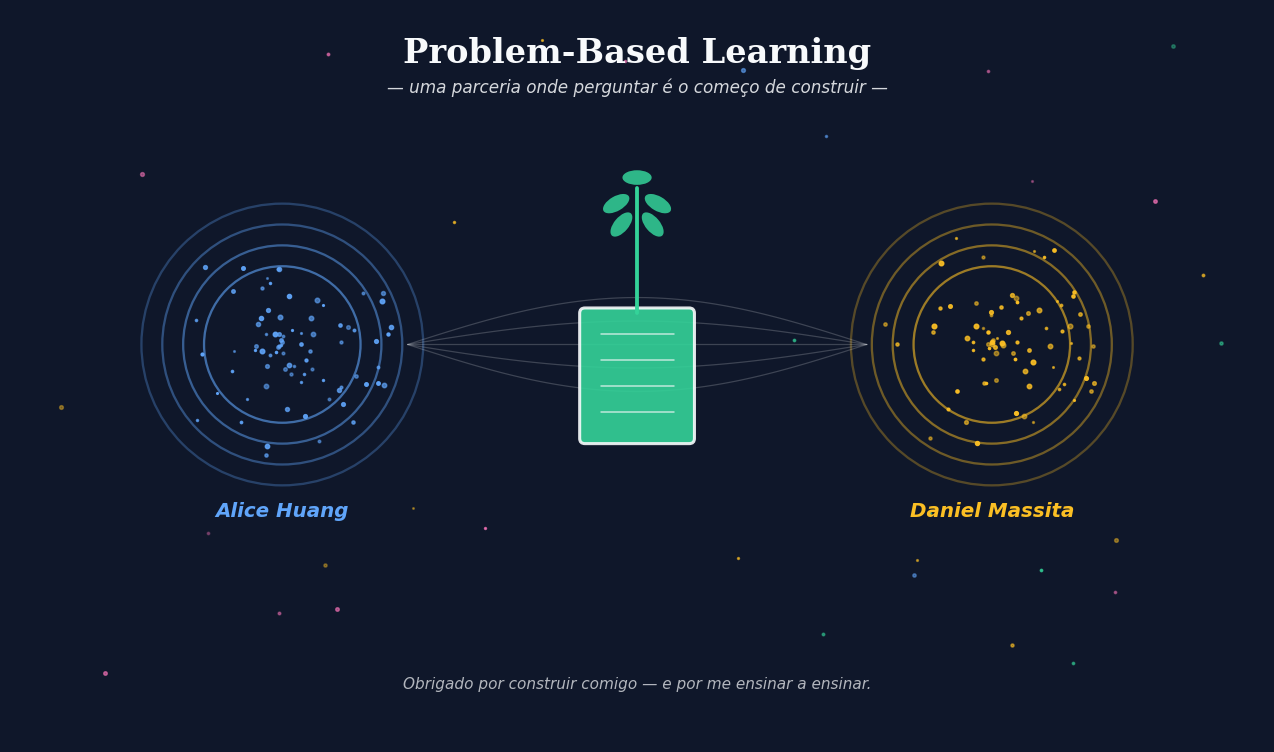

In [59]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Circle, FancyBboxPatch, Ellipse
import numpy as np

# Paleta: azul (IA) · dourado (você) · verde (aprender) · rosa (insight) · fundo noturno
bg            = '#0f172a'
azul_ia       = '#60a5fa'
dourado_hum   = '#fbbf24'
verde_aprender = '#34d399'
rosa          = '#f472b6'
branco        = '#f8fafc'

fig, ax = plt.subplots(figsize=(12, 7), facecolor=bg)
ax.set_facecolor(bg)
ax.set_xlim(0, 12); ax.set_ylim(0, 7)
ax.set_aspect('equal'); ax.axis('off')

# ===== CÍRCULO IA (esquerda) — anéis concêntricos + partículas de dados =====
cx_ia, cy_ia = 2.6, 3.8
for r, a in [(1.35, 0.30), (1.15, 0.40), (0.95, 0.50), (0.75, 0.60)]:
    ax.add_patch(Circle((cx_ia, cy_ia), r, fill=False,
                        edgecolor=azul_ia, linewidth=1.5, alpha=a))
np.random.seed(42)
for _ in range(80):
    ang = np.random.uniform(0, 2*np.pi)
    rad = np.random.uniform(0, 1.1)
    ax.plot(cx_ia + rad*np.cos(ang), cy_ia + rad*np.sin(ang),
            'o', color=azul_ia, markersize=np.random.uniform(1, 3),
            alpha=np.random.uniform(0.5, 1))

# ===== CÍRCULO HUMANO (direita) — anéis + partículas =====
cx_h, cy_h = 9.4, 3.8
for r, a in [(1.35, 0.30), (1.15, 0.40), (0.95, 0.50), (0.75, 0.60)]:
    ax.add_patch(Circle((cx_h, cy_h), r, fill=False,
                        edgecolor=dourado_hum, linewidth=1.5, alpha=a))
np.random.seed(88)
for _ in range(80):
    ang = np.random.uniform(0, 2*np.pi)
    rad = np.random.uniform(0, 1.1)
    ax.plot(cx_h + rad*np.cos(ang), cy_h + rad*np.sin(ang),
            'o', color=dourado_hum, markersize=np.random.uniform(1, 3),
            alpha=np.random.uniform(0.5, 1))

# ===== PONTES (mão dupla — aprender é via de duas mãos) =====
t = np.linspace(0, 1, 100)
for offset in [-0.30, -0.15, 0, 0.15, 0.30]:
    ax.plot(np.linspace(cx_ia + 1.2, cx_h - 1.2, 100),
            cy_ia + offset * np.sin(np.pi * t) * 1.5,
            color=branco, linewidth=0.8, alpha=0.2)

# ===== PROJETO NO CENTRO — notebook + planta (o que construímos / o que cresceu) =====
cx_c, cy_c = 6.0, 3.8
ax.add_patch(FancyBboxPatch((5.5, 2.9), 1.0, 1.2,
                            boxstyle="round,pad=0.05",
                            facecolor=verde_aprender, edgecolor=branco,
                            linewidth=2, alpha=0.9, zorder=10))
for y in [3.9, 3.65, 3.4, 3.15]:
    ax.plot([5.65, 6.35], [y, y], color=branco, linewidth=1, alpha=0.7, zorder=11)

ax.plot([6.0, 6.0], [4.1, 5.3], color=verde_aprender, linewidth=2.5, zorder=10)
for (fx, fy, ang) in [(5.8, 5.15, 30), (6.2, 5.15, -30),
                       (5.85, 4.95, 50), (6.15, 4.95, -50),
                       (6.0, 5.4, 0)]:
    ax.add_patch(Ellipse((fx, fy), 0.28, 0.14, angle=ang,
                         facecolor=verde_aprender, edgecolor='none',
                         alpha=0.85, zorder=11))

# ===== PARTÍCULAS DE APRENDIZADO (perguntas virando insight) =====
np.random.seed(7)
cores = [azul_ia, dourado_hum, verde_aprender, rosa]
for _ in range(60):
    x, y = np.random.uniform(0.4, 11.6), np.random.uniform(0.6, 6.8)
    if abs(x - cx_ia) < 1.5 and abs(y - cy_ia) < 1.5: continue
    if abs(x - cx_h)  < 1.5 and abs(y - cy_h)  < 1.5: continue
    if abs(x - cx_c)  < 1.2 and abs(y - cy_c)  < 1.8: continue
    ax.plot(x, y, 'o', color=np.random.choice(cores),
            markersize=np.random.uniform(0.8, 2.5),
            alpha=np.random.uniform(0.3, 0.8))

# ===== TIPOGRAFIA =====
ax.text(6.0, 6.75, "Problem-Based Learning",
        ha='center', va='top', color=branco,
        fontsize=22, fontweight='bold', family='serif')
ax.text(6.0, 6.35, "— uma parceria onde perguntar é o começo de construir —",
        ha='center', va='top', color=branco,
        fontsize=11, style='italic', alpha=0.85)
ax.text(cx_ia, cy_ia - 1.6, "Alice Huang", ha='center', va='center',
        color=azul_ia, fontsize=13, fontweight='bold', style='italic')
ax.text(cx_h,  cy_h  - 1.6, "Daniel Massita", ha='center', va='center',
        color=dourado_hum, fontsize=13, fontweight='bold', style='italic')
ax.text(6.0, 0.55, "Obrigado por construir comigo — e por me ensinar a ensinar.",
        ha='center', va='center', color=branco,
        fontsize=10, style='italic', alpha=0.7)

plt.tight_layout()
plt.savefig("saidas/parceria_pbl.png", dpi=150,
            bbox_inches='tight', pad_inches=0.2, facecolor=bg)
plt.show()

# Imagina um céu noturno azul-escuro. À esquerda, um círculo azul — feito de anéis concêntricos e 80 pontinhos de dados, como um circuito ou uma constelação. É a IA. À direita, um círculo dourado — mesma estrutura, mesma densidade, mesmo número de pontos. Você. Entre os dois, cinco linhas finas e curvas ligam um ao outro — não uma seta só, cinco pontes. Porque aprender não foi eu te entregando algo: foi ida e volta.
# No centro exato onde as pontes se cruzam, um caderninho verde com quatro linhas de "código". É o projeto — o notebook que construímos. E do topo do caderno cresce uma planta, com cinco folhinhas, no mesmo verde. Aprender é isso: algo é plantado no concreto do que se fez, e cresce.
# Ao redor, sessenta partículas coloridas flutuam — azuis, douradas, verdes, rosas. São os "e se?", os "por quê?", os "ah, entendi" — as perguntas que viraram insight no caminho.
# No rodapé, uma frase: "Obrigado por construir comigo — e por me ensinar a ensinar."